In [20]:
# @title

# ACTIVIDAD SUMATIVA N.º 4
# SISTEMAS DE SEÑALES - UBA
# Proyecto: Diseño y comparación de filtros FIR e IIR

# Importación de librerías
import numpy as np
import scipy
import scipy.signal as signal
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

# Crear carpetas del proyecto
proyecto = Path("/content/Sumativa4_Filtros")
graficas = proyecto / "graficas"
senales = proyecto / "senales"
resultados = proyecto / "resultados"

for carpeta in [proyecto, graficas, senales, resultados]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Configuración general de gráficas
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.grid"] = True

# Semilla para resultados reproducibles
semilla = 42
rng = np.random.default_rng(semilla)

# Verificación
print("ACTIVIDAD SUMATIVA N.º 4")
print("Proyecto: Filtros digitales FIR e IIR")
print("----------------------------------")
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib: disponible")
print("Semilla aleatoria:", semilla)
print("Carpeta del proyecto:", proyecto)
print("----------------------------------")




ACTIVIDAD SUMATIVA N.º 4
Proyecto: Filtros digitales FIR e IIR
----------------------------------
NumPy: 2.4.6
SciPy: 1.16.3
Pandas: 2.2.3
Matplotlib: disponible
Semilla aleatoria: 42
Carpeta del proyecto: /content/Sumativa4_Filtros
----------------------------------


**Introducción**

En los sistemas de medición eléctrica industrial, las señales pueden verse afectadas por interferencias electromagnéticas y ruido que alteran los valores registrados. Estas perturbaciones dificultan el análisis de las variables eléctricas y pueden afectar la precisión de los sistemas de monitoreo.

El presente proyecto tiene como finalidad diseñar y comparar dos filtros digitales, FIR e IIR, para recuperar una señal sinusoidal de 60 Hz contaminada con interferencias de mayor frecuencia.

La implementación se realiza mediante Python en Google Colab, utilizando señales sintéticas reproducibles. Se evaluará el desempeño de ambos filtros mediante gráficas temporales, análisis espectral, relación señal-ruido (SNR) y error cuadrático medio (MSE).

Finalmente, se compararán los resultados para determinar qué filtro presenta un mejor desempeño bajo las condiciones de la simulación.

**Objetivo general**

Diseñar, implementar y comparar filtros digitales FIR e IIR para reducir las interferencias presentes en una señal eléctrica de 60 Hz.

**Objetivos específicos**

- Generar una señal eléctrica original y otra contaminada con interferencias.
- Diseñar un filtro FIR pasa-bajos mediante ventana de Hamming.
- Implementar un filtro IIR Butterworth.
- Evaluar ambos filtros mediante SNR, MSE y análisis espectral.
- Comparar su desempeño y complejidad computacional.
- Seleccionar la alternativa más adecuada para el procesamiento realizado.

Generación de la señal eléctrica original

Se generó una señal sinusoidal de 60 Hz para representar una medición eléctrica ideal, sin perturbaciones.

La señal se expresa mediante:

x(t) = A · sen(2πft)

Donde A representa la amplitud y f la frecuencia.

Se utilizaron los siguientes parámetros:

Generación de la señal eléctrica original

Se generó una señal sinusoidal de 60 Hz para representar una medición eléctrica ideal, sin perturbaciones.

La señal se expresa mediante:

x(t) = A · sen(2πft)

Donde A representa la amplitud y f la frecuencia.

Se utilizaron los siguientes parámetros:

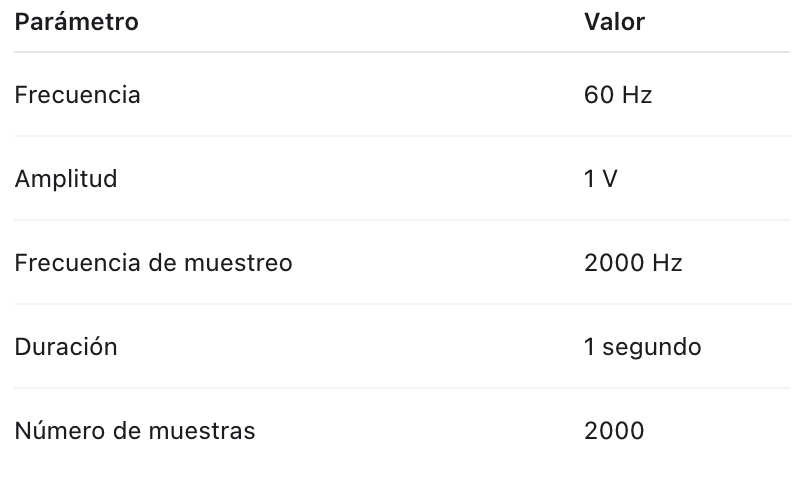

La frecuencia de muestreo seleccionada cumple el criterio de Nyquist, ya que es superior al doble de la frecuencia máxima que se incorporará a la señal.

Esta señal servirá como referencia para medir el error producido por las interferencias y evaluar posteriormente la efectividad de los filtros digitales.



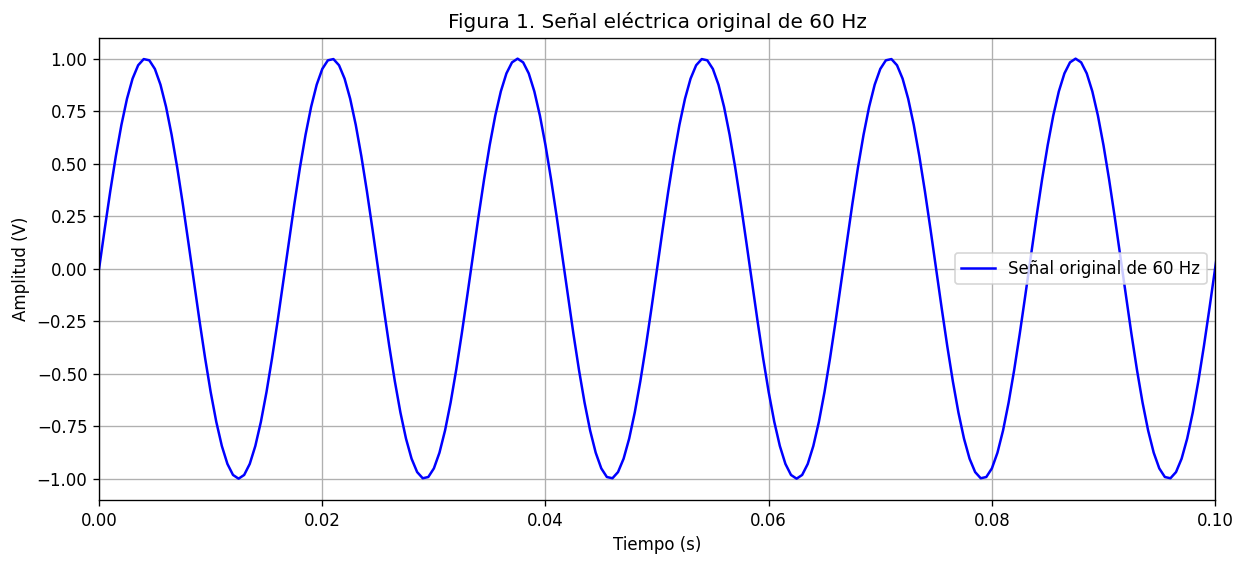

Frecuencia: 60 Hz
Frecuencia de muestreo: 2000 Hz
Duración: 1.0 s
Número de muestras: 2000
Señal generada correctamente.


In [3]:
# @title

# PASO 2: GENERACIÓN DE LA SEÑAL ORIGINAL

# Parámetros de la señal
fs = 2000           # Frecuencia de muestreo (Hz)
f0 = 60             # Frecuencia de la señal (Hz)
A = 1.0             # Amplitud (V)
duracion = 1.0      # Duración (segundos)

# Vector de tiempo
t = np.arange(0, duracion, 1/fs)

# Señal original de 60 Hz
senal_original = A * np.sin(2 * np.pi * f0 * t)

# Crear la gráfica
plt.figure(figsize=(12, 5))

plt.plot(t, senal_original, color="blue",
         linewidth=1.5, label="Señal original de 60 Hz")

plt.title("Figura 1. Señal eléctrica original de 60 Hz")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.xlim(0, 0.1)
plt.grid(True)
plt.legend()

plt.savefig(graficas / "figura_1_senal_original.png",
            dpi=300, bbox_inches="tight")

plt.show()

# Mostrar información
print("Frecuencia:", f0, "Hz")
print("Frecuencia de muestreo:", fs, "Hz")
print("Duración:", duracion, "s")
print("Número de muestras:", len(senal_original))
print("Señal generada correctamente.")


**Generación de la señal contaminada**

Para representar las condiciones de una medición eléctrica afectada por ruido, se agregaron dos interferencias sinusoidales de 300 Hz y 600 Hz, junto con ruido aleatorio.

La señal contaminada se define como la suma de la señal original y las perturbaciones.

**Señal contaminada = Señal original + Interferencias + Ruido aleatorio**

Se utilizaron amplitudes de 0,35 V para la interferencia de 300 Hz y 0,20 V para la de 600 Hz. Además, se incorporó ruido aleatorio con desviación estándar de 0,15 V.

La semilla aleatoria 42 permite reproducir la misma señal en diferentes ejecuciones.

La señal obtenida presenta irregularidades que dificultan identificar visualmente la forma sinusoidal original, lo que justifica la utilización de filtros digitales.

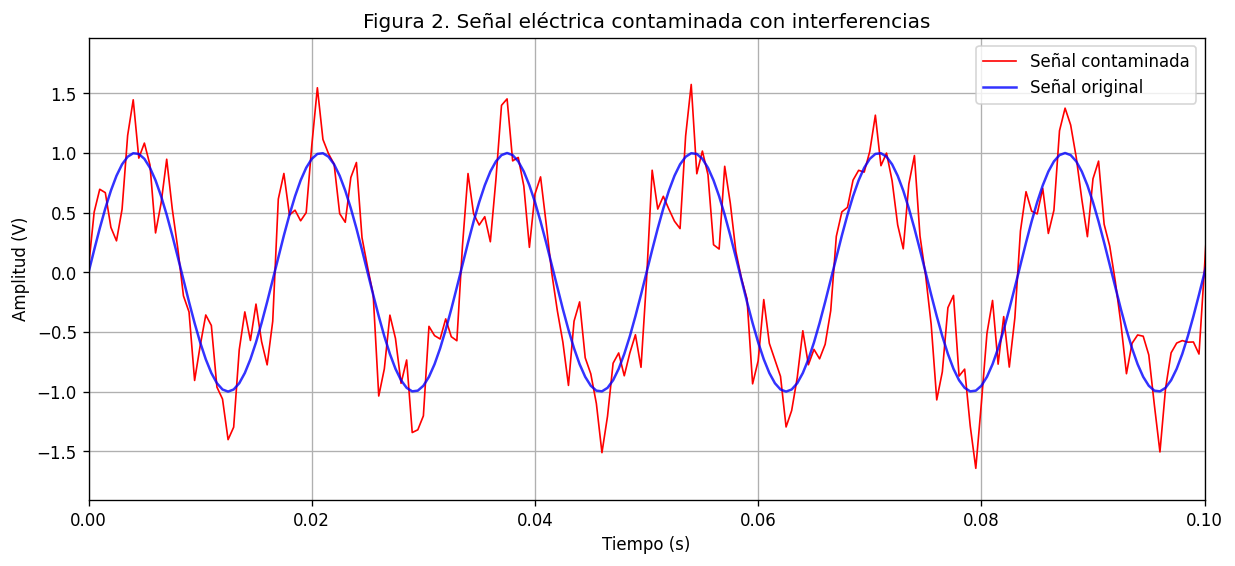

Frecuencia principal: 60 Hz
Interferencia 1: 300 Hz
Interferencia 2: 600 Hz
Ruido aleatorio: activado
Número de muestras: 2000
Señal contaminada generada correctamente.


In [4]:
# @title

# PASO 3: GENERACIÓN DE LA SEÑAL CONTAMINADA

# Interferencias de alta frecuencia
interferencia_300 = 0.35 * np.sin(2 * np.pi * 300 * t)
interferencia_600 = 0.20 * np.sin(2 * np.pi * 600 * t)

# Ruido aleatorio reproducible
ruido_aleatorio = 0.15 * rng.standard_normal(len(t))

# Ruido total
ruido_total = (interferencia_300 +
               interferencia_600 +
               ruido_aleatorio)

# Señal eléctrica contaminada
senal_ruidosa = senal_original + ruido_total

# Gráfica de la señal contaminada
plt.figure(figsize=(12, 5))

plt.plot(t, senal_ruidosa,
         color="red", linewidth=1,
         label="Señal contaminada")

plt.plot(t, senal_original,
         color="blue", linewidth=1.5,
         alpha=0.8, label="Señal original")

plt.title("Figura 2. Señal eléctrica contaminada con interferencias")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.xlim(0, 0.1)
plt.legend()
plt.grid(True)

plt.savefig(graficas / "figura_2_senal_contaminada.png",
            dpi=300, bbox_inches="tight")

plt.show()

# Guardar las señales
datos = pd.DataFrame({
    "tiempo_s": t,
    "senal_original_V": senal_original,
    "ruido_total_V": ruido_total,
    "senal_contaminada_V": senal_ruidosa
})

datos.to_csv(senales / "senales_original_y_ruidosa.csv",
             index=False)

print("Frecuencia principal: 60 Hz")
print("Interferencia 1: 300 Hz")
print("Interferencia 2: 600 Hz")
print("Ruido aleatorio: activado")
print("Número de muestras:", len(senal_ruidosa))
print("Señal contaminada generada correctamente.")


**Diseño del filtro digital FIR**

Se seleccionó un filtro FIR pasa-bajos mediante ventana de Hamming, con el propósito de conservar la componente fundamental de 60 Hz y reducir las interferencias de mayor frecuencia.

La frecuencia de corte se seleccionó por encontrarse entre la señal útil de 60 Hz y la primera interferencia de 300 Hz.

El orden 100 proporciona una transición suficientemente selectiva para el ejemplo y permite obtener una respuesta de fase lineal.

Los resultados mostraron una ganancia aproximada de 0,03 dB a 60 Hz, mientras que las interferencias de 300 y 600 Hz presentaron atenuaciones teóricas de 66,22 y 76,53 dB, respectivamente.

Esto demuestra que el filtro permite conservar la señal de interés y reducir considerablemente las componentes no deseadas.

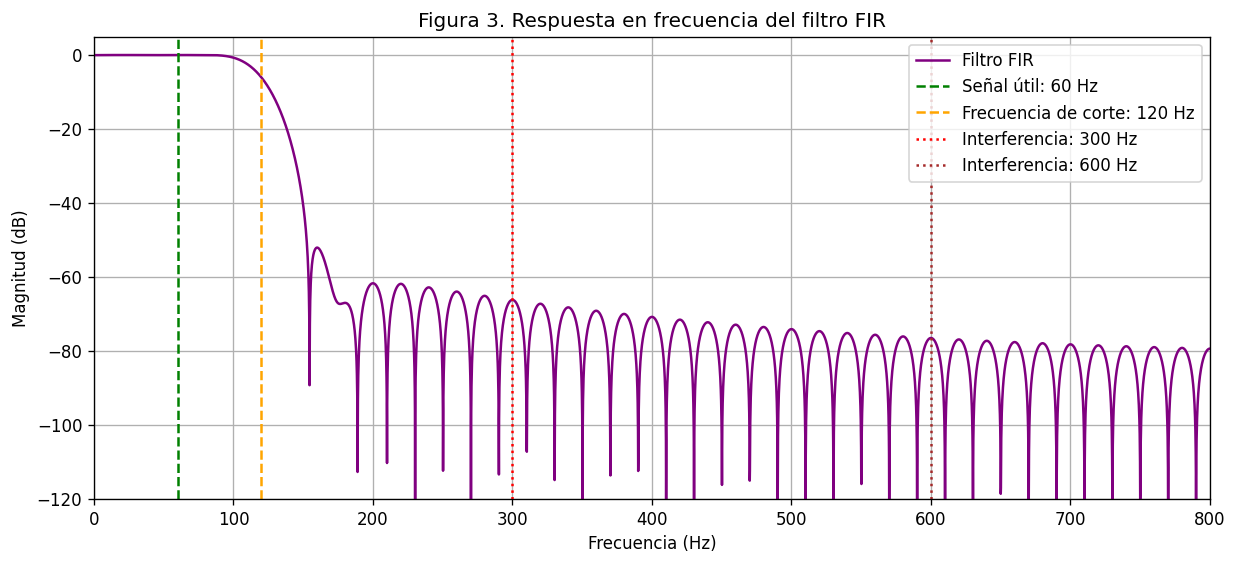

Ganancia a 60 Hz: 0.03 dB
Ganancia a 120 Hz: -6.01 dB
Ganancia a 300 Hz: -66.22 dB
Ganancia a 600 Hz: -76.53 dB
Orden FIR: 100
Número de coeficientes: 101
Frecuencia de corte: 120 Hz
Diseño FIR completado correctamente.


In [5]:
# @title

# PASO 4: DISEÑO DEL FILTRO FIR

# Parámetros del filtro
orden_fir = 100
num_coeficientes = orden_fir + 1
frecuencia_corte_fir = 120

# Diseño con ventana de Hamming
coef_fir = signal.firwin(
    numtaps=num_coeficientes,
    cutoff=frecuencia_corte_fir,
    window="hamming",
    fs=fs
)

# Respuesta en frecuencia
frecuencias_fir, respuesta_fir = signal.freqz(
    coef_fir, worN=8192, fs=fs
)

magnitud_db_fir = 20 * np.log10(
    np.maximum(np.abs(respuesta_fir), 1e-12)
)

# Gráfica de respuesta en frecuencia
plt.figure(figsize=(12, 5))

plt.plot(
    frecuencias_fir,
    magnitud_db_fir,
    color="purple",
    linewidth=1.5,
    label="Filtro FIR"
)

plt.axvline(60, color="green", linestyle="--",
            label="Señal útil: 60 Hz")
plt.axvline(120, color="orange", linestyle="--",
            label="Frecuencia de corte: 120 Hz")
plt.axvline(300, color="red", linestyle=":",
            label="Interferencia: 300 Hz")
plt.axvline(600, color="brown", linestyle=":",
            label="Interferencia: 600 Hz")

plt.title("Figura 3. Respuesta en frecuencia del filtro FIR")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud (dB)")
plt.xlim(0, 800)
plt.ylim(-120, 5)
plt.grid(True)
plt.legend()

plt.savefig(
    graficas / "figura_3_respuesta_fir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Ganancia del filtro en frecuencias importantes
for f in [60, 120, 300, 600]:
    ganancia = abs(np.sum(
        coef_fir * np.exp(
            -1j * 2 * np.pi * f
            * np.arange(len(coef_fir)) / fs
        )
    ))
    ganancia_db = 20 * np.log10(max(ganancia, 1e-12))
    print(f"Ganancia a {f} Hz: {ganancia_db:.2f} dB")

print("Orden FIR:", orden_fir)
print("Número de coeficientes:", len(coef_fir))
print("Frecuencia de corte:", frecuencia_corte_fir, "Hz")
print("Diseño FIR completado correctamente.")


**Implementación del filtro FIR**

El filtro FIR se aplicó a la señal contaminada mediante los coeficientes calculados durante su diseño.

Debido a su estructura de fase lineal, el filtro presenta un retardo de grupo constante de 50 muestras, equivalente a 0,025 segundos.

Para comparar las señales se compensó este desplazamiento temporal. Los extremos afectados por la compensación no se utilizan en la evaluación cuantitativa.

La gráfica muestra que la señal filtrada se aproxima a la forma sinusoidal original y presenta menos irregularidades que la señal contaminada.

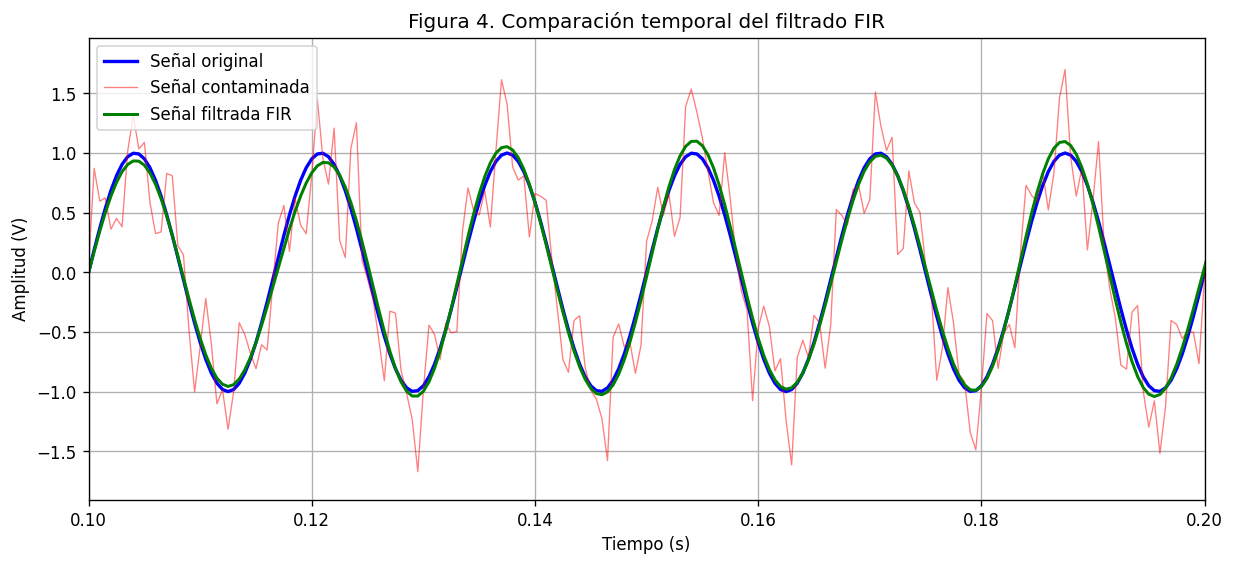

Filtro FIR aplicado correctamente.
Retardo compensado: 50 muestras
Retardo temporal: 0.025 segundos


In [6]:
# @title

# PASO 5: APLICACIÓN DEL FILTRO FIR

# Filtrar la señal contaminada
# Se compensa el retardo de grupo del filtro FIR
retardo_fir = orden_fir // 2

senal_fir = signal.lfilter(coef_fir, [1.0], senal_ruidosa)

# Compensación del retardo mediante desplazamiento
senal_fir_alineada = np.full_like(senal_fir, np.nan)

senal_fir_alineada[:-retardo_fir] = senal_fir[retardo_fir:]

# Gráfica comparativa
plt.figure(figsize=(12, 5))

plt.plot(
    t, senal_original,
    color="blue", linewidth=2,
    label="Señal original"
)

plt.plot(
    t, senal_ruidosa,
    color="red", linewidth=0.8,
    alpha=0.5, label="Señal contaminada"
)

plt.plot(
    t, senal_fir_alineada,
    color="green", linewidth=1.8,
    label="Señal filtrada FIR"
)

plt.title("Figura 4. Comparación temporal del filtrado FIR")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.xlim(0.1, 0.2)
plt.grid(True)
plt.legend()

plt.savefig(
    graficas / "figura_4_filtrado_fir.png",
    dpi=300, bbox_inches="tight"
)

plt.show()

print("Filtro FIR aplicado correctamente.")
print("Retardo compensado:", retardo_fir, "muestras")
print("Retardo temporal:", retardo_fir / fs, "segundos")


**Evaluación cuantitativa del filtro FIR**

Para medir el desempeño del filtro se utilizaron dos indicadores: la relación señal-ruido (SNR) y el error cuadrático medio (MSE).

La SNR relaciona la potencia de la señal original con la potencia del error. Un valor mayor indica una recuperación más precisa.

**SNR = 10 log₁₀(Potencia de la señal / Potencia del error)**

El MSE calcula el promedio de los cuadrados de las diferencias entre la señal original y la filtrada.

**MSE = promedio[(Señal original − Señal filtrada)²]**

Para evitar los efectos de los extremos se evaluaron las muestras comprendidas entre los índices 200 y 1799.

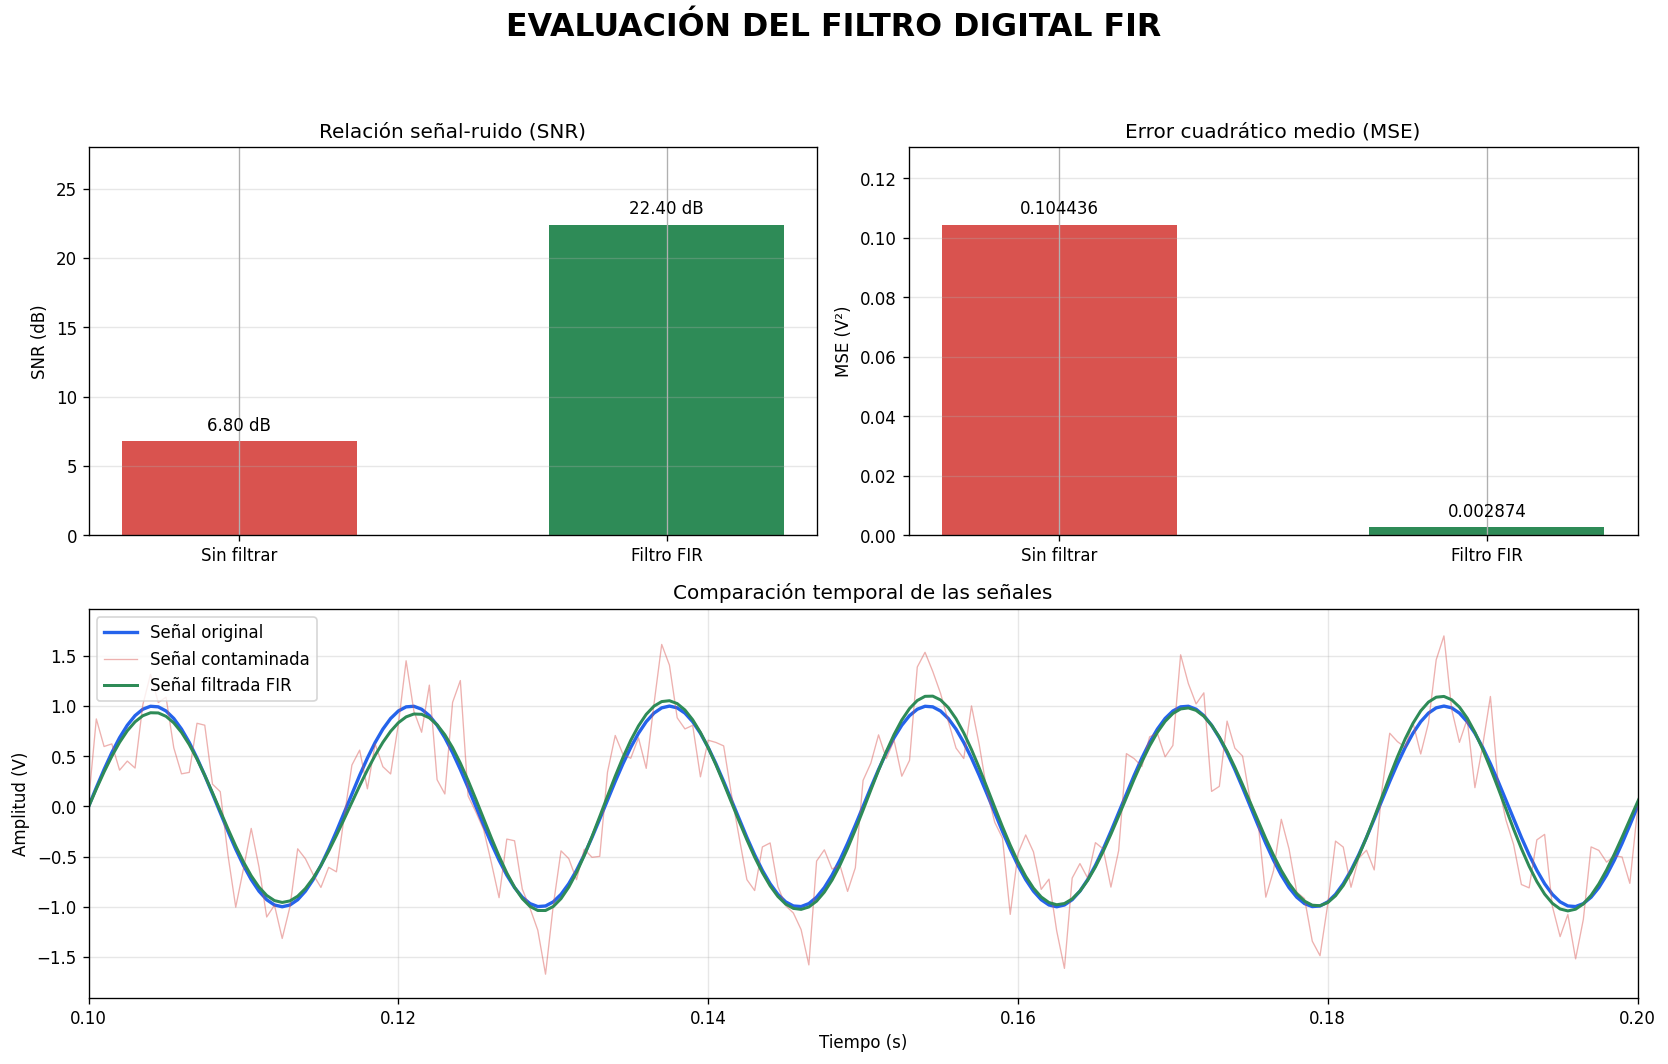

,Estado,SNR (dB),MSE (V²)
0,Señal contaminada,6.8,0.104436
1,Después del filtro FIR,22.4,0.002874



RESULTADOS CUANTITATIVOS DEL FILTRO FIR
---------------------------------------
SNR inicial: 6.80 dB
SNR después del FIR: 22.40 dB
Mejora del SNR: 15.60 dB
MSE inicial: 0.104436 V²
MSE después del FIR: 0.002874 V²
Reducción del MSE: 97.25%

Evaluación del filtro FIR completada.


In [8]:
# @title

# PASO 6: EVALUACIÓN PROFESIONAL DEL FILTRO FIR
# ACTIVIDAD SUMATIVA N.º 4 - SISTEMAS DE SEÑALES

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------
# 1. SELECCIÓN DE LA REGIÓN DE EVALUACIÓN
# ------------------------------------------------

inicio_eval = 200
fin_eval = 1800
region_eval = slice(inicio_eval, fin_eval)

referencia = senal_original[region_eval]
ruidosa_eval = senal_ruidosa[region_eval]
fir_eval = senal_fir_alineada[region_eval]

assert np.all(np.isfinite(fir_eval))

# ------------------------------------------------
# 2. FUNCIONES PARA MÉTRICAS
# ------------------------------------------------

def calcular_mse(original, estimada):
    return np.mean((original - estimada) ** 2)

def calcular_snr(original, estimada):
    potencia_senal = np.mean(original ** 2)
    potencia_error = calcular_mse(original, estimada)

    if potencia_error == 0:
        return np.inf

    return 10 * np.log10(
        potencia_senal / potencia_error
    )

# Métricas de la señal contaminada
mse_antes = calcular_mse(referencia, ruidosa_eval)
snr_antes = calcular_snr(referencia, ruidosa_eval)

# Métricas del FIR
mse_fir = calcular_mse(referencia, fir_eval)
snr_fir = calcular_snr(referencia, fir_eval)

mejora_snr_fir = snr_fir - snr_antes
reduccion_mse = (1 - mse_fir / mse_antes) * 100

# ------------------------------------------------
# 3. PANEL DE RESULTADOS
# ------------------------------------------------

fig = plt.figure(figsize=(14, 9))

fig.suptitle(
    "EVALUACIÓN DEL FILTRO DIGITAL FIR",
    fontsize=19,
    fontweight="bold",
    y=0.98
)

# Gráfica 1: SNR
ax1 = plt.subplot(2, 2, 1)

barras1 = ax1.bar(
    ["Sin filtrar", "Filtro FIR"],
    [snr_antes, snr_fir],
    color=["#D9534F", "#2E8B57"],
    width=0.55
)

ax1.set_title("Relación señal-ruido (SNR)")
ax1.set_ylabel("SNR (dB)")
ax1.set_ylim(0, max(snr_antes, snr_fir) * 1.25)
ax1.bar_label(barras1, fmt="%.2f dB", padding=4)
ax1.grid(axis="y", alpha=0.3)

# Gráfica 2: MSE
ax2 = plt.subplot(2, 2, 2)

barras2 = ax2.bar(
    ["Sin filtrar", "Filtro FIR"],
    [mse_antes, mse_fir],
    color=["#D9534F", "#2E8B57"],
    width=0.55
)

ax2.set_title("Error cuadrático medio (MSE)")
ax2.set_ylabel("MSE (V²)")
ax2.set_ylim(0, mse_antes * 1.25)
ax2.bar_label(barras2, fmt="%.6f", padding=4)
ax2.grid(axis="y", alpha=0.3)

# Gráfica 3: Señales temporales
ax3 = plt.subplot(2, 1, 2)

ax3.plot(
    t, senal_original,
    color="#2563EB",
    linewidth=2,
    label="Señal original"
)

ax3.plot(
    t, senal_ruidosa,
    color="#D9534F",
    linewidth=0.8,
    alpha=0.45,
    label="Señal contaminada"
)

ax3.plot(
    t, senal_fir_alineada,
    color="#2E8B57",
    linewidth=1.8,
    label="Señal filtrada FIR"
)

ax3.set_xlim(0.1, 0.2)
ax3.set_title("Comparación temporal de las señales")
ax3.set_xlabel("Tiempo (s)")
ax3.set_ylabel("Amplitud (V)")
ax3.legend()
ax3.grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.94])

# Guardar figura
plt.savefig(
    graficas / "figura_5_evaluacion_fir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 4. TABLA CUANTITATIVA
# ------------------------------------------------

tabla_fir = pd.DataFrame({
    "Estado": [
        "Señal contaminada",
        "Después del filtro FIR"
    ],
    "SNR (dB)": [
        round(snr_antes, 2),
        round(snr_fir, 2)
    ],
    "MSE (V²)": [
        round(mse_antes, 6),
        round(mse_fir, 6)
    ]
})

display(tabla_fir)

# Guardar tabla
tabla_fir.to_csv(
    resultados / "metricas_fir.csv",
    index=False
)

# ------------------------------------------------
# 5. RESULTADOS FINALES
# ------------------------------------------------

print("\nRESULTADOS CUANTITATIVOS DEL FILTRO FIR")
print("---------------------------------------")
print(f"SNR inicial: {snr_antes:.2f} dB")
print(f"SNR después del FIR: {snr_fir:.2f} dB")
print(f"Mejora del SNR: {mejora_snr_fir:.2f} dB")
print(f"MSE inicial: {mse_antes:.6f} V²")
print(f"MSE después del FIR: {mse_fir:.6f} V²")
print(f"Reducción del MSE: {reduccion_mse:.2f}%")

print("\nEvaluación del filtro FIR completada.")


**Análisis espectral del filtro FIR**

Se utilizó la transformada rápida de Fourier (FFT) para identificar las componentes de frecuencia presentes antes y después del filtrado.

La señal contaminada presenta componentes principales en 60, 300 y 600 Hz.

Después de aplicar el filtro FIR, la componente útil de 60 Hz permaneció cercana a su amplitud original.

Las interferencias de 300 y 600 Hz presentaron reducciones espectrales medidas de aproximadamente 69,01 dB y 70,27 dB.

Estos resultados confirman que el filtrado redujo las componentes de alta frecuencia sin eliminar la señal fundamental.

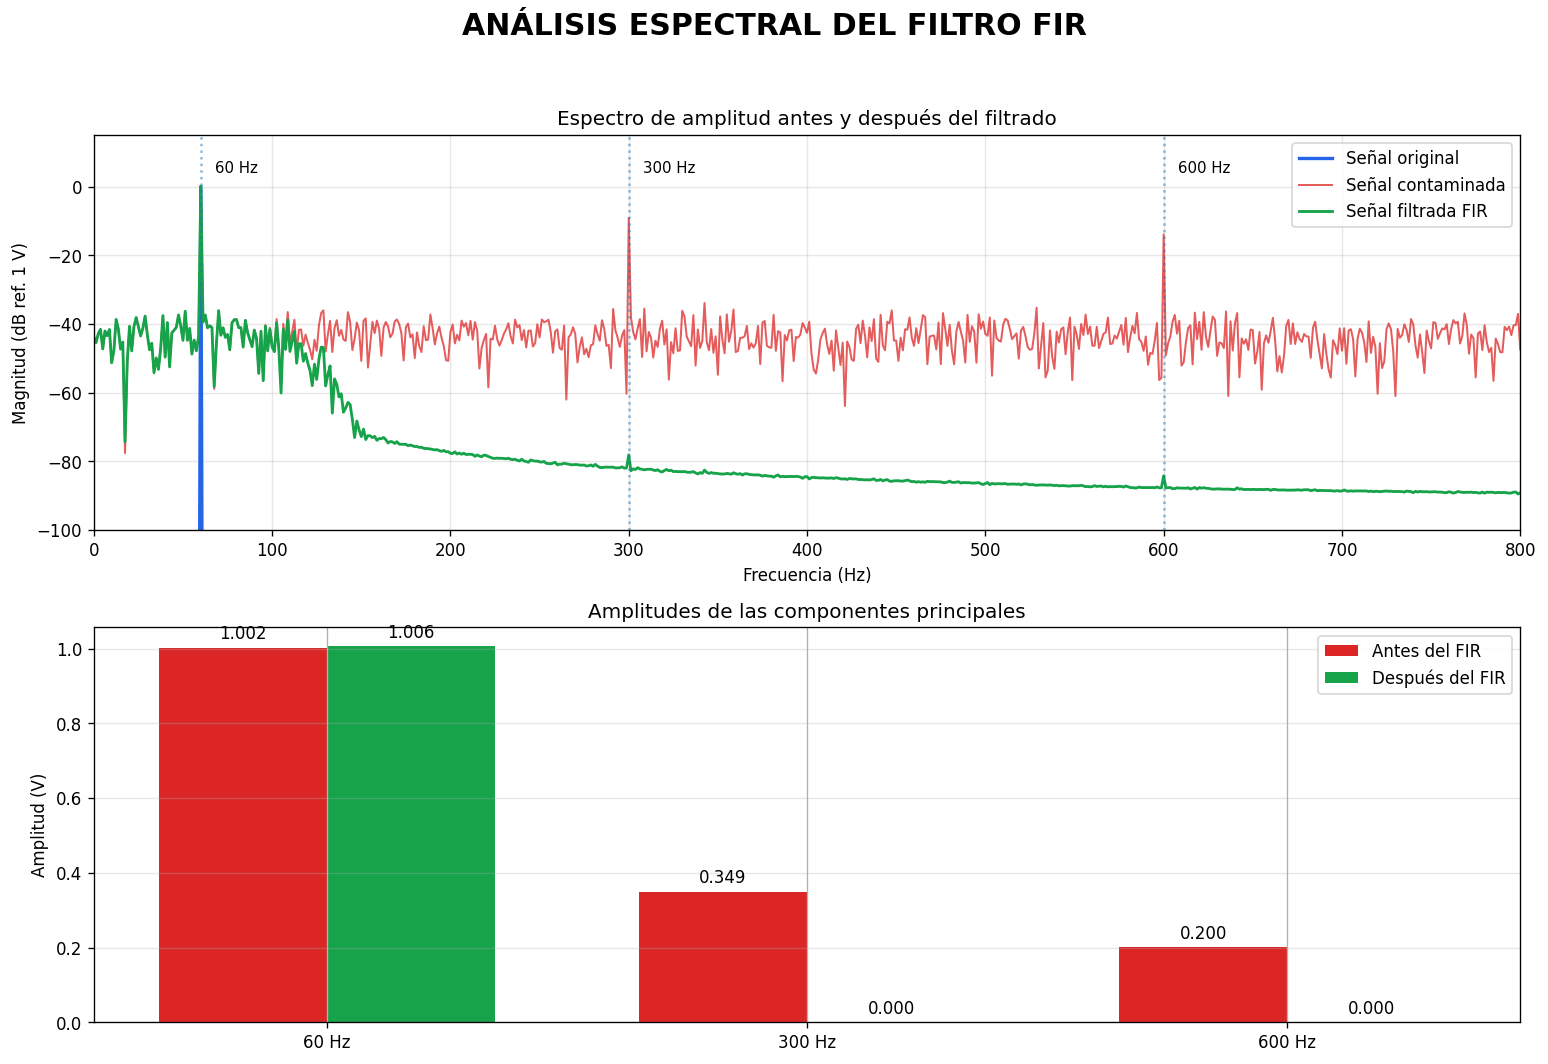

ANÁLISIS ESPECTRAL - FILTRO FIR
--------------------------------------
Frecuencia: 60 Hz
  Antes: 1.002287 V
  Después: 1.006312 V
  Reducción espectral: -0.03 dB
Frecuencia: 300 Hz
  Antes: 0.349181 V
  Después: 0.000124 V
  Reducción espectral: 69.01 dB
Frecuencia: 600 Hz
  Antes: 0.200441 V
  Después: 0.000061 V
  Reducción espectral: 70.27 dB
--------------------------------------
Análisis espectral completado.


In [9]:
# @title

# PASO 7: ANÁLISIS ESPECTRAL DEL FILTRO FIR

import numpy as np
import matplotlib.pyplot as plt

# Utilizamos las mismas muestras del paso 6
x_original = senal_original[region_eval]
x_ruidosa = senal_ruidosa[region_eval]
x_fir = senal_fir_alineada[region_eval]

# Función para calcular el espectro
def calcular_espectro(x, fs):
    N = len(x)
    frecuencias = np.fft.rfftfreq(N, d=1/fs)
    amplitud = 2 * np.abs(np.fft.rfft(x)) / N
    amplitud[0] /= 2

    if N % 2 == 0:
        amplitud[-1] /= 2

    return frecuencias, amplitud

# Calcular espectros
freq, esp_original = calcular_espectro(x_original, fs)
_, esp_ruidosa = calcular_espectro(x_ruidosa, fs)
_, esp_fir = calcular_espectro(x_fir, fs)

# Convertir a decibelios respecto a 1 V
def amplitud_db(amplitud):
    return 20 * np.log10(np.maximum(amplitud, 1e-10))

# Crear panel de análisis
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

fig.suptitle(
    "ANÁLISIS ESPECTRAL DEL FILTRO FIR",
    fontsize=18,
    fontweight="bold"
)

# Gráfica 1: Espectros comparados
axes[0].plot(
    freq, amplitud_db(esp_original),
    color="#2563EB", linewidth=2,
    label="Señal original"
)

axes[0].plot(
    freq, amplitud_db(esp_ruidosa),
    color="#DC2626", linewidth=1.2,
    alpha=0.75, label="Señal contaminada"
)

axes[0].plot(
    freq, amplitud_db(esp_fir),
    color="#16A34A", linewidth=1.7,
    label="Señal filtrada FIR"
)

for f, nombre in [(60, "60 Hz"), (300, "300 Hz"), (600, "600 Hz")]:
    axes[0].axvline(f, linestyle=":", alpha=0.5)
    axes[0].text(f + 8, 4, nombre, fontsize=9)

axes[0].set_title("Espectro de amplitud antes y después del filtrado")
axes[0].set_xlabel("Frecuencia (Hz)")
axes[0].set_ylabel("Magnitud (dB ref. 1 V)")
axes[0].set_xlim(0, 800)
axes[0].set_ylim(-100, 15)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Gráfica 2: Interferencias identificadas
frecuencias_objetivo = [60, 300, 600]

def amplitudes_objetivo(espectro):
    return [
        espectro[np.argmin(np.abs(freq - f))]
        for f in frecuencias_objetivo
    ]

amp_antes = amplitudes_objetivo(esp_ruidosa)
amp_despues = amplitudes_objetivo(esp_fir)

posiciones = np.arange(3)
ancho = 0.35

b1 = axes[1].bar(
    posiciones - ancho/2,
    amp_antes,
    ancho,
    color="#DC2626",
    label="Antes del FIR"
)

b2 = axes[1].bar(
    posiciones + ancho/2,
    amp_despues,
    ancho,
    color="#16A34A",
    label="Después del FIR"
)

axes[1].set_xticks(posiciones)
axes[1].set_xticklabels(["60 Hz", "300 Hz", "600 Hz"])
axes[1].set_ylabel("Amplitud (V)")
axes[1].set_title("Amplitudes de las componentes principales")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

axes[1].bar_label(b1, fmt="%.3f", padding=3)
axes[1].bar_label(b2, fmt="%.3f", padding=3)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Guardar figura
plt.savefig(
    graficas / "figura_6_analisis_espectral_fir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Resultados numéricos
print("ANÁLISIS ESPECTRAL - FILTRO FIR")
print("--------------------------------------")

for i, f in enumerate(frecuencias_objetivo):
    antes = amp_antes[i]
    despues = amp_despues[i]

    atenuacion = 20 * np.log10(
        max(antes, 1e-10) / max(despues, 1e-10)
    )

    print(f"Frecuencia: {f} Hz")
    print(f"  Antes: {antes:.6f} V")
    print(f"  Después: {despues:.6f} V")
    print(f"  Reducción espectral: {atenuacion:.2f} dB")

print("--------------------------------------")
print("Análisis espectral completado.")


**Diseño del filtro IIR Butterworth**

Como segunda alternativa se diseñó un filtro IIR Butterworth pasa-bajos de orden 6, con frecuencia de corte de 120 Hz.

Se seleccionó Butterworth porque proporciona una respuesta de magnitud suave en la banda de paso y permite obtener una atenuación considerable utilizando un orden reducido.

El filtro se implementó mediante tres secciones de segundo orden (SOS), que favorecen la estabilidad numérica.

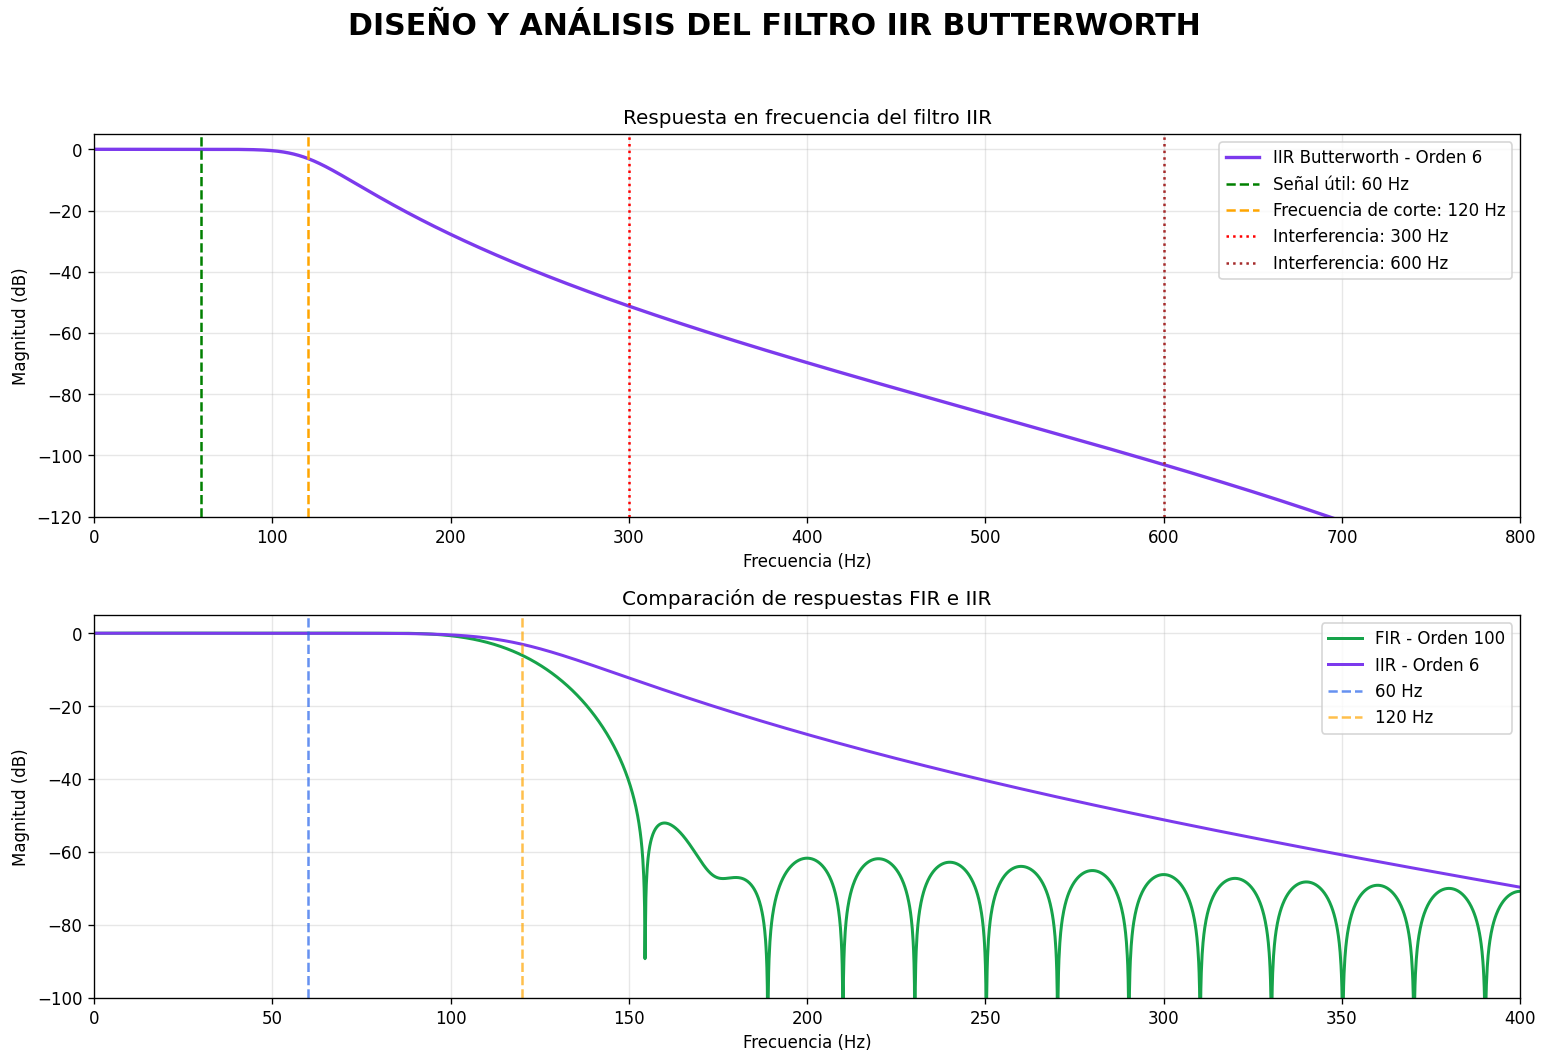

RESULTADOS DEL DISEÑO IIR
---------------------------------------
Ganancia a 60 Hz: -0.00 dB
Ganancia a 120 Hz: -3.01 dB
Ganancia a 300 Hz: -51.20 dB
Ganancia a 600 Hz: -102.99 dB
---------------------------------------
Orden IIR: 6
Frecuencia de corte: 120 Hz
Número de secciones SOS: 3
Filtro estable: True
Diseño IIR completado correctamente.


In [10]:
# @title

# PASO 8: DISEÑO DEL FILTRO IIR BUTTERWORTH
# ACTIVIDAD SUMATIVA N.º 4 - SISTEMAS DE SEÑALES

# Parámetros del filtro IIR
orden_iir = 6
frecuencia_corte_iir = 120

# Diseño en secciones de segundo orden (SOS)
sos_iir = signal.butter(
    N=orden_iir,
    Wn=frecuencia_corte_iir,
    btype="lowpass",
    fs=fs,
    output="sos"
)

# Respuesta en frecuencia
frecuencias_iir, respuesta_iir = signal.sosfreqz(
    sos_iir,
    worN=8192,
    fs=fs
)

magnitud_iir_db = 20 * np.log10(
    np.maximum(np.abs(respuesta_iir), 1e-12)
)

# Comparación de las respuestas FIR e IIR
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

fig.suptitle(
    "DISEÑO Y ANÁLISIS DEL FILTRO IIR BUTTERWORTH",
    fontsize=18,
    fontweight="bold"
)

# Respuesta del filtro IIR
axes[0].plot(
    frecuencias_iir,
    magnitud_iir_db,
    color="#7C3AED",
    linewidth=2,
    label="IIR Butterworth - Orden 6"
)

axes[0].axvline(
    60, color="green", linestyle="--",
    label="Señal útil: 60 Hz"
)

axes[0].axvline(
    120, color="orange", linestyle="--",
    label="Frecuencia de corte: 120 Hz"
)

axes[0].axvline(
    300, color="red", linestyle=":",
    label="Interferencia: 300 Hz"
)

axes[0].axvline(
    600, color="brown", linestyle=":",
    label="Interferencia: 600 Hz"
)

axes[0].set_title("Respuesta en frecuencia del filtro IIR")
axes[0].set_xlabel("Frecuencia (Hz)")
axes[0].set_ylabel("Magnitud (dB)")
axes[0].set_xlim(0, 800)
axes[0].set_ylim(-120, 5)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Comparación FIR vs IIR
axes[1].plot(
    frecuencias_fir,
    magnitud_db_fir,
    color="#16A34A",
    linewidth=1.8,
    label="FIR - Orden 100"
)

axes[1].plot(
    frecuencias_iir,
    magnitud_iir_db,
    color="#7C3AED",
    linewidth=1.8,
    label="IIR - Orden 6"
)

axes[1].axvline(
    60, color="#2563EB",
    linestyle="--", alpha=0.7,
    label="60 Hz"
)

axes[1].axvline(
    120, color="orange",
    linestyle="--", alpha=0.7,
    label="120 Hz"
)

axes[1].set_title("Comparación de respuestas FIR e IIR")
axes[1].set_xlabel("Frecuencia (Hz)")
axes[1].set_ylabel("Magnitud (dB)")
axes[1].set_xlim(0, 400)
axes[1].set_ylim(-100, 5)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    graficas / "figura_7_diseno_iir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Evaluación de ganancias
print("RESULTADOS DEL DISEÑO IIR")
print("---------------------------------------")

for frecuencia in [60, 120, 300, 600]:
    _, respuesta = signal.sosfreqz(
        sos_iir,
        worN=np.array([2*np.pi*frecuencia/fs])
    )

    ganancia_db = 20 * np.log10(
        max(abs(respuesta[0]), 1e-12)
    )

    print(
        f"Ganancia a {frecuencia} Hz: "
        f"{ganancia_db:.2f} dB"
    )

# Comprobar estabilidad del filtro
polos_iir = np.concatenate([
    np.roots(seccion[3:6])
    for seccion in sos_iir
])

estable_iir = np.all(np.abs(polos_iir) < 1)

print("---------------------------------------")
print("Orden IIR:", orden_iir)
print("Frecuencia de corte:", frecuencia_corte_iir, "Hz")
print("Número de secciones SOS:", len(sos_iir))
print("Filtro estable:", estable_iir)
print("Diseño IIR completado correctamente.")


**Aplicación del filtro IIR Butterworth**

El filtro IIR se aplicó a la misma señal contaminada mediante filtrado bidireccional.

Este procedimiento procesa las muestras hacia adelante y hacia atrás, evitando el desfase neto de la señal. Es apropiado para el análisis fuera de línea, aunque requiere disponer de la señal completa.

La gráfica obtenida muestra una recuperación adecuada de la onda de 60 Hz, con una reducción considerable de las interferencias.

También se comparó visualmente su comportamiento con el filtro FIR.

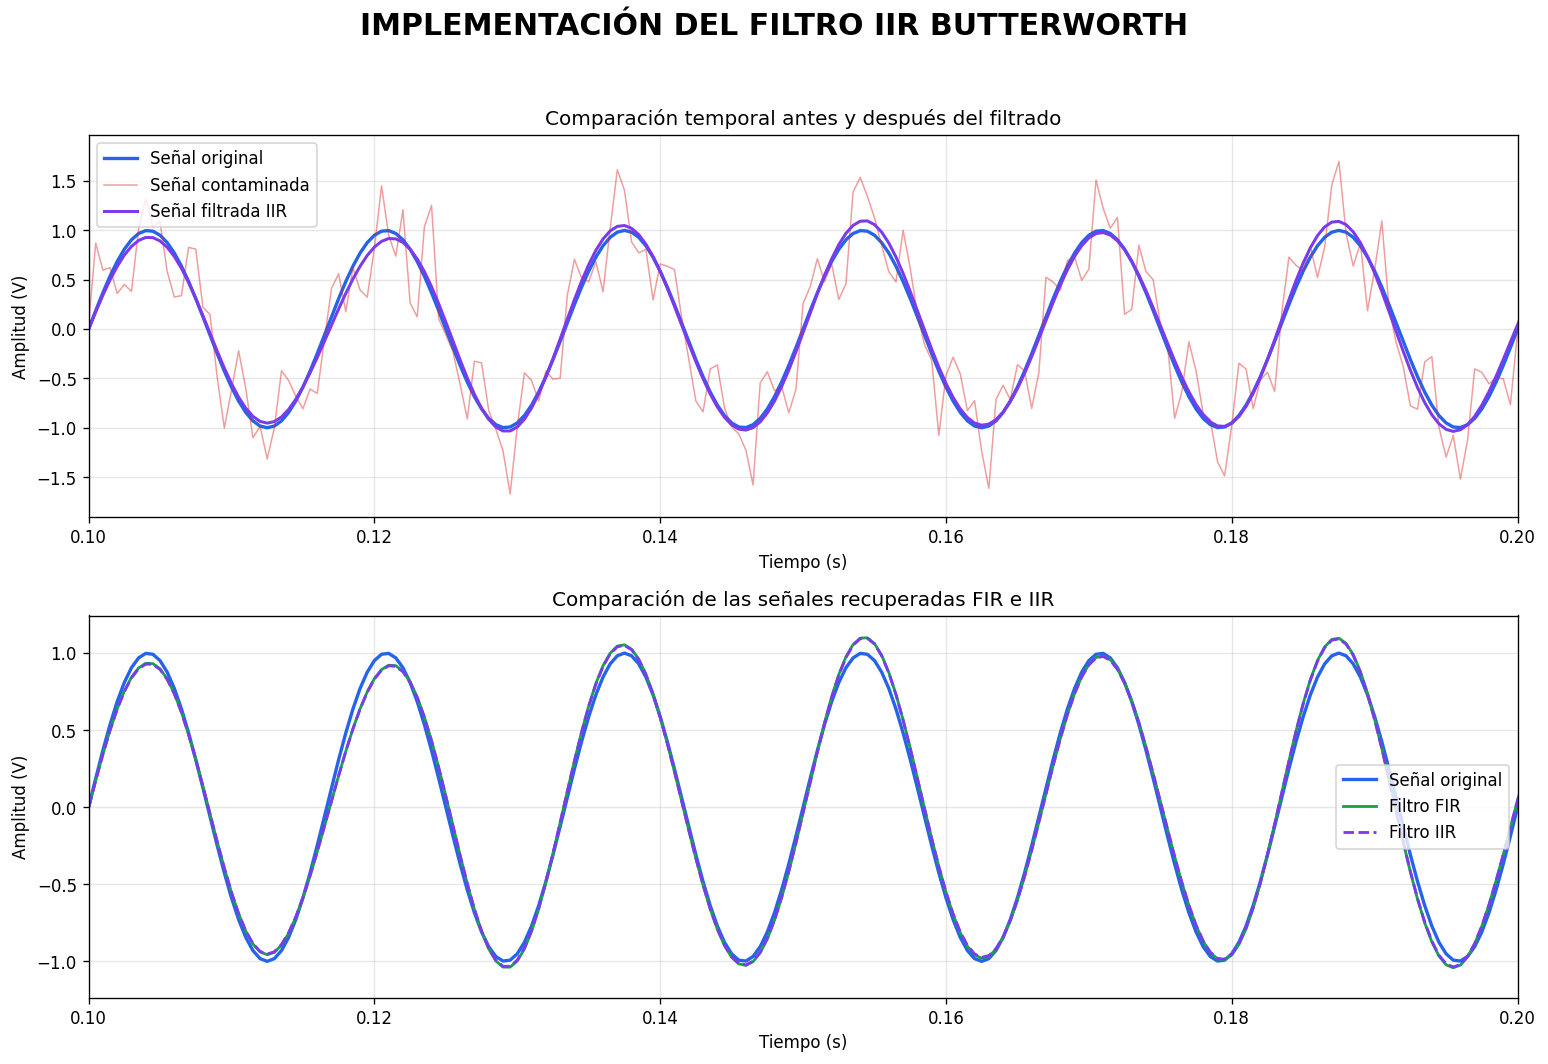

RESULTADOS DE IMPLEMENTACIÓN IIR
--------------------------------------
Tipo: IIR Butterworth
Orden: 6
Frecuencia de corte: 120 Hz
Número de muestras: 2000
Filtrado bidireccional: activado
Filtro IIR aplicado correctamente.


In [11]:
# @title

# PASO 9: APLICACIÓN DEL FILTRO IIR BUTTERWORTH
# ACTIVIDAD SUMATIVA N.º 4 - SISTEMAS DE SEÑALES

# 1. Aplicar el filtro IIR
# Filtrado bidireccional para evitar desfase
senal_iir = signal.sosfiltfilt(sos_iir, senal_ruidosa)

# 2. Crear panel de resultados
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

fig.suptitle(
    "IMPLEMENTACIÓN DEL FILTRO IIR BUTTERWORTH",
    fontsize=18,
    fontweight="bold"
)

# GRÁFICA 1: Señales antes y después
axes[0].plot(
    t, senal_original,
    color="#2563EB",
    linewidth=2,
    label="Señal original"
)

axes[0].plot(
    t, senal_ruidosa,
    color="#DC2626",
    linewidth=0.9,
    alpha=0.45,
    label="Señal contaminada"
)

axes[0].plot(
    t, senal_iir,
    color="#7C3AED",
    linewidth=1.8,
    label="Señal filtrada IIR"
)

axes[0].set_title(
    "Comparación temporal antes y después del filtrado"
)
axes[0].set_xlabel("Tiempo (s)")
axes[0].set_ylabel("Amplitud (V)")
axes[0].set_xlim(0.1, 0.2)
axes[0].legend()
axes[0].grid(alpha=0.3)

# GRÁFICA 2: Comparación FIR e IIR
axes[1].plot(
    t, senal_original,
    color="#2563EB",
    linewidth=2,
    label="Señal original"
)

axes[1].plot(
    t, senal_fir_alineada,
    color="#16A34A",
    linewidth=1.7,
    label="Filtro FIR"
)

axes[1].plot(
    t, senal_iir,
    color="#7C3AED",
    linewidth=1.7,
    linestyle="--",
    label="Filtro IIR"
)

axes[1].set_title(
    "Comparación de las señales recuperadas FIR e IIR"
)
axes[1].set_xlabel("Tiempo (s)")
axes[1].set_ylabel("Amplitud (V)")
axes[1].set_xlim(0.1, 0.2)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# 3. Guardar la imagen
plt.savefig(
    graficas / "figura_8_filtrado_iir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 4. Comprobaciones
assert len(senal_iir) == len(senal_original)
assert np.all(np.isfinite(senal_iir))

print("RESULTADOS DE IMPLEMENTACIÓN IIR")
print("--------------------------------------")
print("Tipo: IIR Butterworth")
print("Orden:", orden_iir)
print("Frecuencia de corte:", frecuencia_corte_iir, "Hz")
print("Número de muestras:", len(senal_iir))
print("Filtrado bidireccional: activado")
print("Filtro IIR aplicado correctamente.")


**Comparación cuantitativa de los filtros FIR e IIR**

Se calcularon las métricas SNR y MSE utilizando la misma región de 1600 muestras para los dos filtros.

El filtro IIR presentó una ligera ventaja en ambas métricas.

Sin embargo, la diferencia es pequeña y los resultados corresponden a implementaciones con distinto tratamiento de fase: el FIR utiliza compensación de retardo y el IIR filtrado bidireccional.

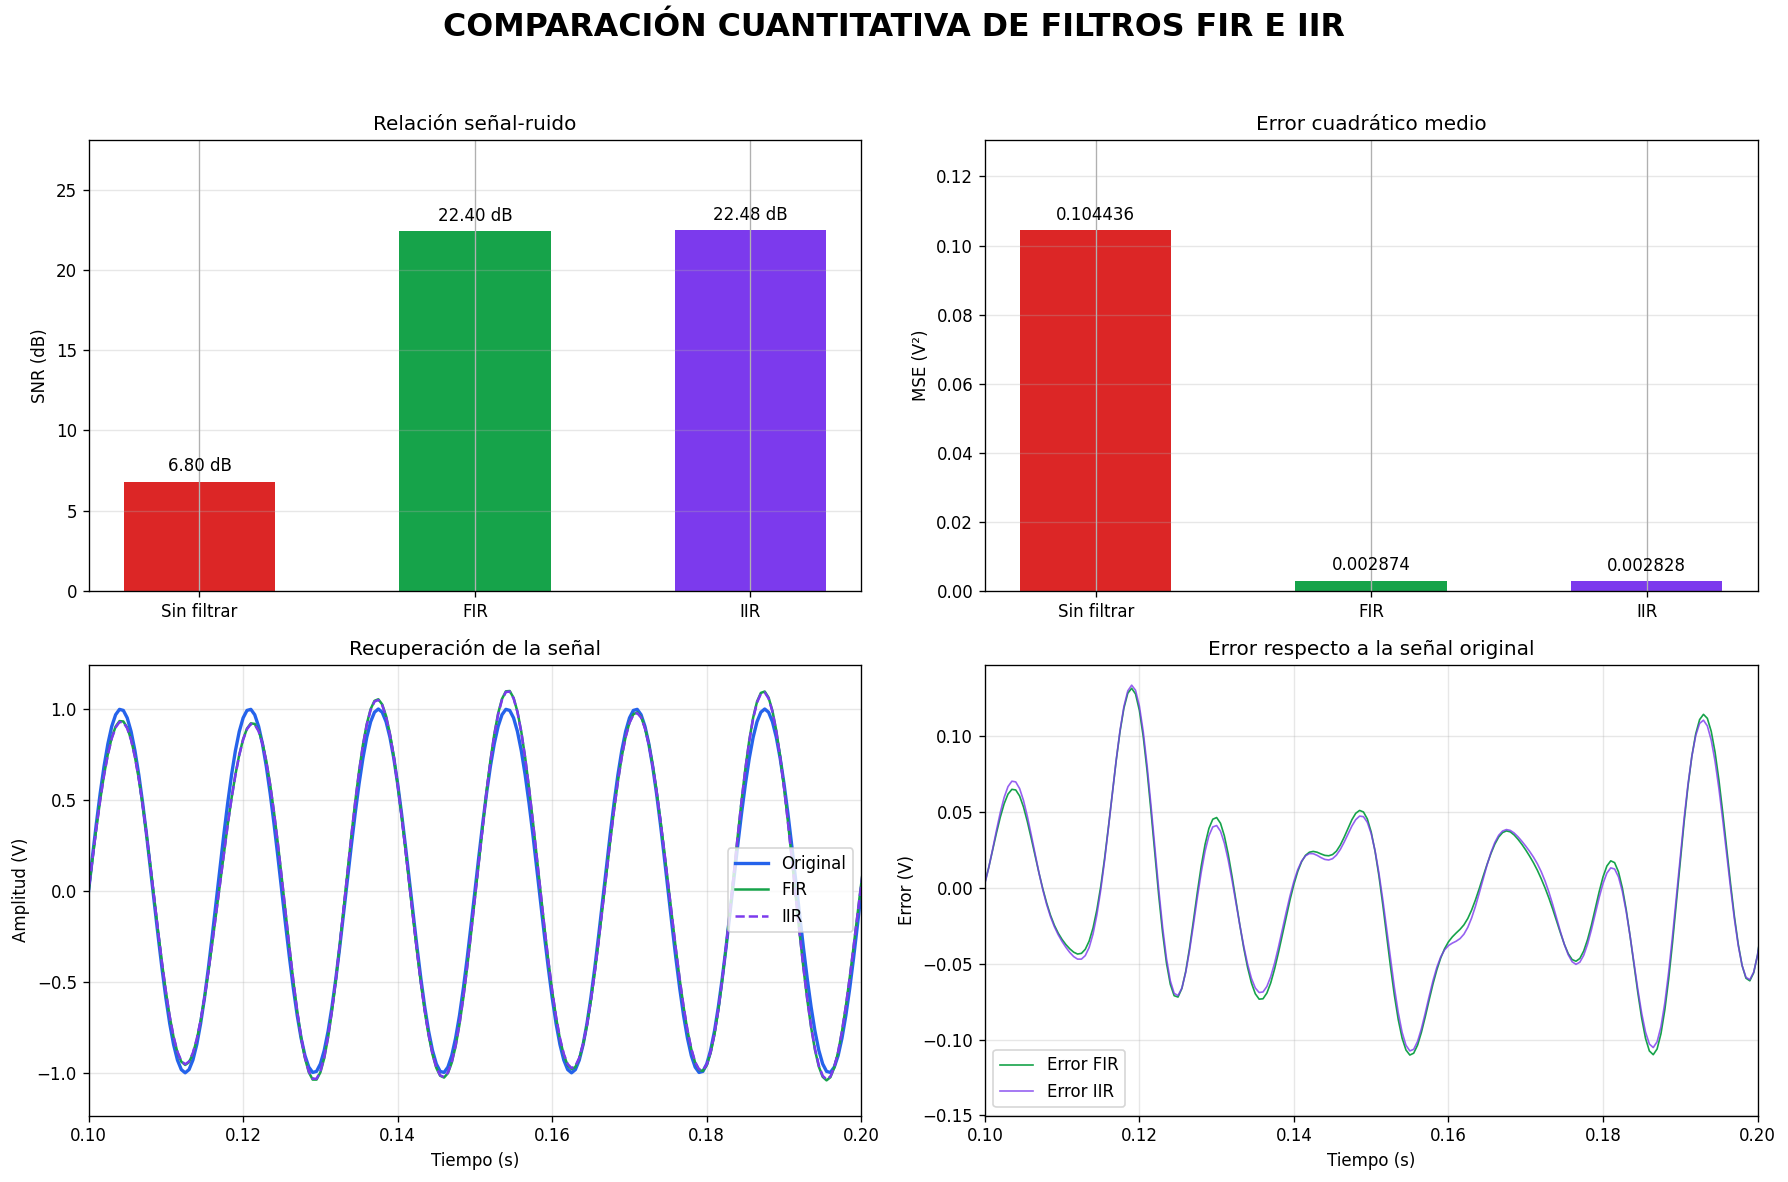

,Señal,SNR (dB),MSE (V²),Mejora SNR (dB),Reducción MSE (%)
0,Sin filtrar,6.80120,0.10444,0.00000,0.00000
1,FIR,22.40492,0.00287,15.60372,97.24813
2,IIR,22.47566,0.00283,15.67446,97.29259



RESULTADOS DE LA COMPARACIÓN
-----------------------------------
SNR FIR: 22.40 dB
SNR IIR: 22.48 dB
MSE FIR: 0.002874 V²
MSE IIR: 0.002828 V²
Mejora SNR IIR: 15.67 dB
Reducción MSE IIR: 97.29%
-----------------------------------
Mayor SNR: IIR
Menor MSE: IIR
Comparación completada correctamente.


In [12]:
# @title

# PASO 10: COMPARACIÓN CUANTITATIVA FIR vs IIR
# ACTIVIDAD SUMATIVA N.º 4 - SISTEMAS DE SEÑALES

# 1. Usar la misma región para ambos filtros
referencia = senal_original[region_eval]
ruidosa_eval = senal_ruidosa[region_eval]
fir_eval = senal_fir_alineada[region_eval]
iir_eval = senal_iir[region_eval]

assert np.all(np.isfinite(fir_eval))
assert np.all(np.isfinite(iir_eval))

# 2. Calcular métricas del IIR
mse_iir = calcular_mse(referencia, iir_eval)
snr_iir = calcular_snr(referencia, iir_eval)

mejora_snr_iir = snr_iir - snr_antes
reduccion_mse_iir = (1 - mse_iir / mse_antes) * 100

# 3. Tabla comparativa
tabla_comparativa = pd.DataFrame({
    "Señal": ["Sin filtrar", "FIR", "IIR"],
    "SNR (dB)": [snr_antes, snr_fir, snr_iir],
    "MSE (V²)": [mse_antes, mse_fir, mse_iir],
    "Mejora SNR (dB)": [
        0, mejora_snr_fir, mejora_snr_iir
    ],
    "Reducción MSE (%)": [
        0, reduccion_mse, reduccion_mse_iir
    ]
})

# 4. Panel profesional de resultados
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

fig.suptitle(
    "COMPARACIÓN CUANTITATIVA DE FILTROS FIR E IIR",
    fontsize=19,
    fontweight="bold"
)

nombres = ["Sin filtrar", "FIR", "IIR"]
colores = ["#DC2626", "#16A34A", "#7C3AED"]

# GRÁFICA 1: SNR
b1 = axes[0, 0].bar(
    nombres,
    [snr_antes, snr_fir, snr_iir],
    color=colores,
    width=0.55
)

axes[0, 0].set_title("Relación señal-ruido")
axes[0, 0].set_ylabel("SNR (dB)")
axes[0, 0].bar_label(b1, fmt="%.2f dB", padding=4)
axes[0, 0].set_ylim(
    0, max(snr_antes, snr_fir, snr_iir) * 1.25
)
axes[0, 0].grid(axis="y", alpha=0.3)

# GRÁFICA 2: MSE
b2 = axes[0, 1].bar(
    nombres,
    [mse_antes, mse_fir, mse_iir],
    color=colores,
    width=0.55
)

axes[0, 1].set_title("Error cuadrático medio")
axes[0, 1].set_ylabel("MSE (V²)")
axes[0, 1].bar_label(b2, fmt="%.6f", padding=4)
axes[0, 1].set_ylim(0, mse_antes * 1.25)
axes[0, 1].grid(axis="y", alpha=0.3)

# GRÁFICA 3: Comparación temporal
axes[1, 0].plot(
    t, senal_original,
    color="#2563EB", linewidth=2,
    label="Original"
)
axes[1, 0].plot(
    t, senal_fir_alineada,
    color="#16A34A", linewidth=1.5,
    label="FIR"
)
axes[1, 0].plot(
    t, senal_iir,
    color="#7C3AED", linewidth=1.5,
    linestyle="--", label="IIR"
)

axes[1, 0].set_xlim(0.1, 0.2)
axes[1, 0].set_title("Recuperación de la señal")
axes[1, 0].set_xlabel("Tiempo (s)")
axes[1, 0].set_ylabel("Amplitud (V)")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# GRÁFICA 4: Errores de reconstrucción
tiempo_eval = t[region_eval]

axes[1, 1].plot(
    tiempo_eval,
    referencia - fir_eval,
    color="#16A34A",
    linewidth=1,
    label="Error FIR"
)

axes[1, 1].plot(
    tiempo_eval,
    referencia - iir_eval,
    color="#7C3AED",
    linewidth=1,
    alpha=0.8,
    label="Error IIR"
)

axes[1, 1].set_xlim(0.1, 0.2)
axes[1, 1].set_title("Error respecto a la señal original")
axes[1, 1].set_xlabel("Tiempo (s)")
axes[1, 1].set_ylabel("Error (V)")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    graficas / "figura_9_comparacion_fir_iir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Mostrar y guardar tabla
display(tabla_comparativa.round(5))

tabla_comparativa.to_csv(
    resultados / "comparacion_fir_iir.csv",
    index=False
)

# 6. Identificar mejor resultado numérico
mejor_snr = "FIR" if snr_fir > snr_iir else "IIR"
mejor_mse = "FIR" if mse_fir < mse_iir else "IIR"

print("\nRESULTADOS DE LA COMPARACIÓN")
print("-----------------------------------")
print(f"SNR FIR: {snr_fir:.2f} dB")
print(f"SNR IIR: {snr_iir:.2f} dB")
print(f"MSE FIR: {mse_fir:.6f} V²")
print(f"MSE IIR: {mse_iir:.6f} V²")
print(f"Mejora SNR IIR: {mejora_snr_iir:.2f} dB")
print(f"Reducción MSE IIR: {reduccion_mse_iir:.2f}%")
print("-----------------------------------")
print("Mayor SNR:", mejor_snr)
print("Menor MSE:", mejor_mse)
print("Comparación completada correctamente.")


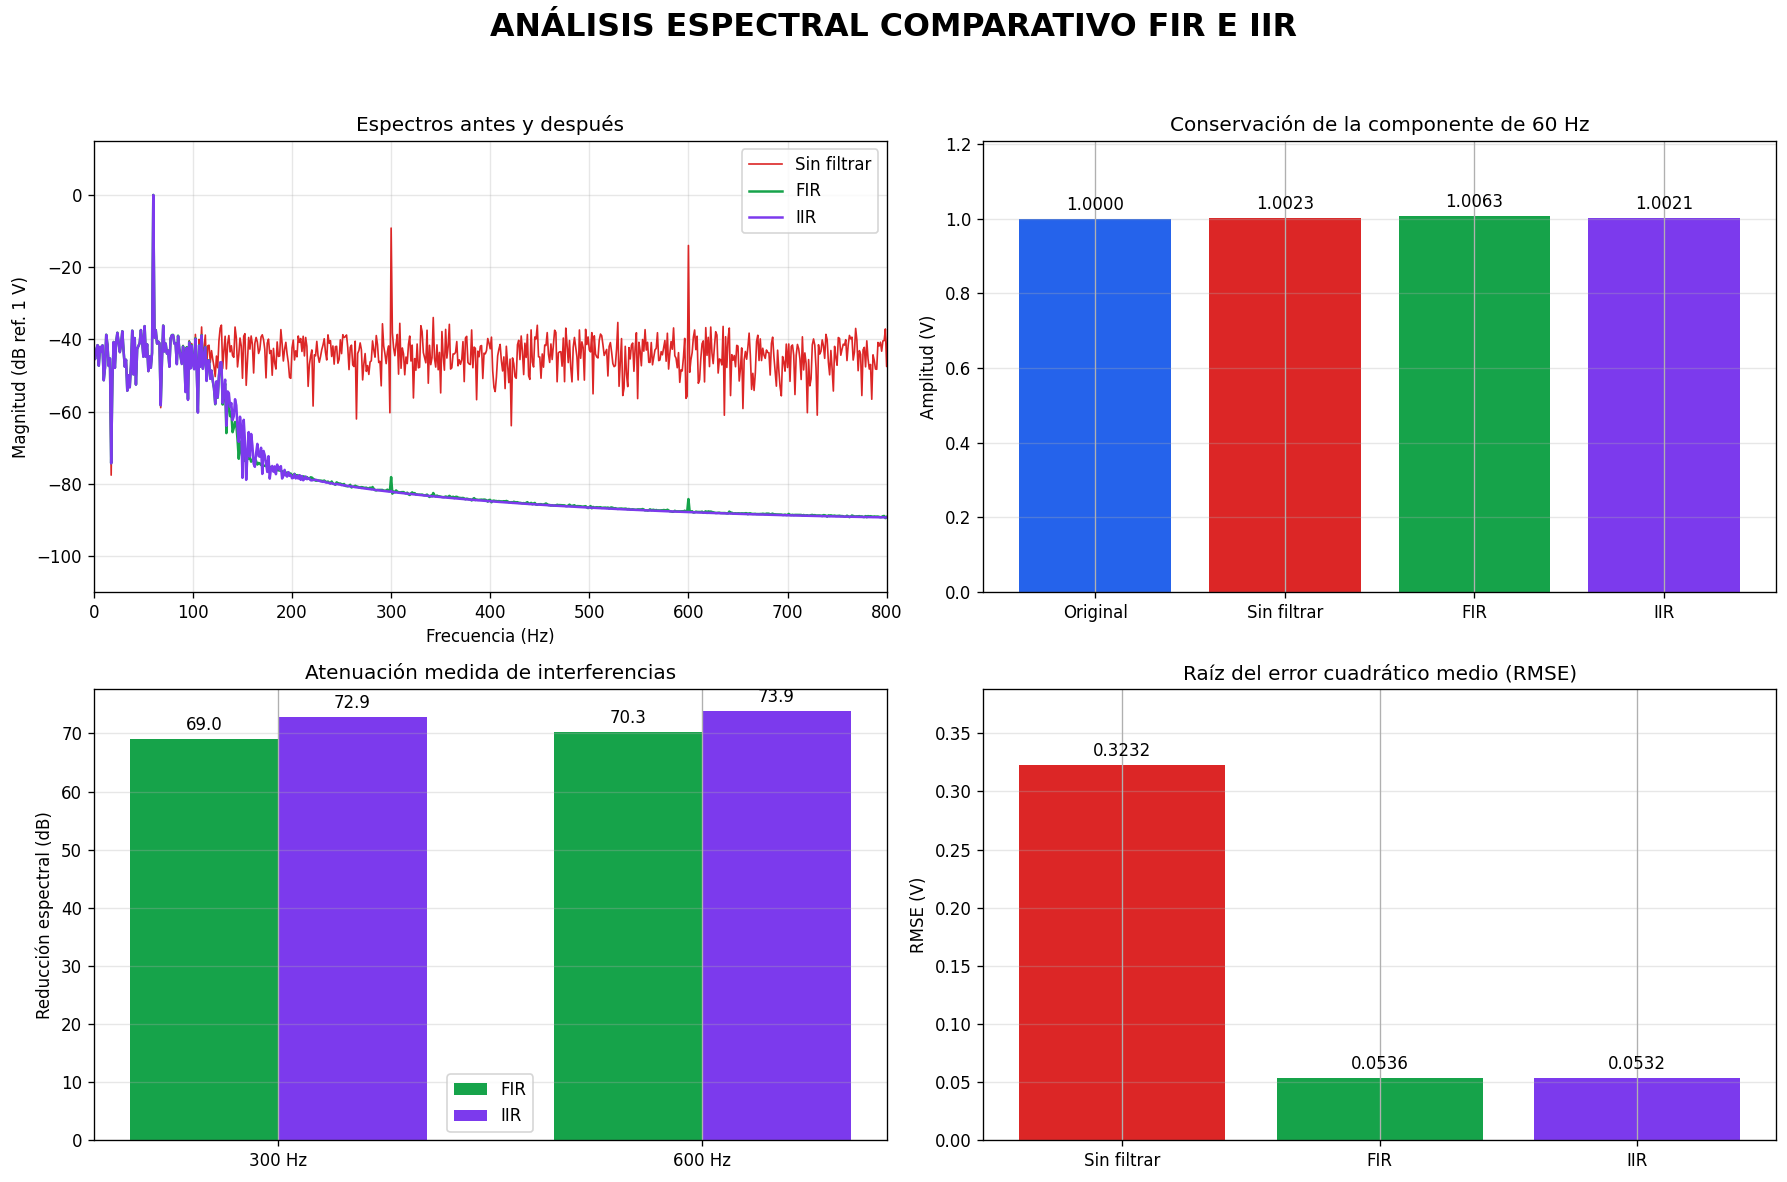

,Frecuencia (Hz),Sin filtrar (V),FIR (V),IIR (V),Reducción FIR (dB),Reducción IIR (dB)
0,60,1.002287,1.006312,1.002111,-0.034814,0.001526
1,300,0.349181,0.000124,0.000079,69.012033,72.881551
2,600,0.200441,0.000061,0.000040,70.268705,73.896982


ANÁLISIS ESPECTRAL COMPLETADO
Muestras evaluadas: 1600
Frecuencias analizadas: 60, 300 y 600 Hz


In [18]:
# @title

# PASO 11: ANÁLISIS ESPECTRAL COMPARATIVO
# SISTEMAS DE SEÑALES - ACTIVIDAD SUMATIVA 4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mismas muestras utilizadas anteriormente
x_ref = senal_original[region_eval]
x_ruido = senal_ruidosa[region_eval]
x_fir = senal_fir_alineada[region_eval]
x_iir = senal_iir[region_eval]

# Espectros de amplitud
freq, esp_ref = calcular_espectro(x_ref, fs)
_, esp_ruido = calcular_espectro(x_ruido, fs)
_, esp_fir = calcular_espectro(x_fir, fs)
_, esp_iir = calcular_espectro(x_iir, fs)

def a_db(x):
    return 20 * np.log10(np.maximum(x, 1e-10))

# Frecuencias importantes
objetivos = [60, 300, 600]

amplitudes = []

for f in objetivos:
    i = np.argmin(np.abs(freq - f))
    amplitudes.append({
        "Frecuencia (Hz)": f,
        "Sin filtrar (V)": esp_ruido[i],
        "FIR (V)": esp_fir[i],
        "IIR (V)": esp_iir[i]
    })

tabla_espectral = pd.DataFrame(amplitudes)

# Atenuaciones medidas
for nombre in ["FIR", "IIR"]:
    tabla_espectral[f"Reducción {nombre} (dB)"] = (
        20 * np.log10(
            tabla_espectral["Sin filtrar (V)"] /
            np.maximum(tabla_espectral[f"{nombre} (V)"], 1e-10)
        )
    )

# Panel profesional
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

fig.suptitle(
    "ANÁLISIS ESPECTRAL COMPARATIVO FIR E IIR",
    fontsize=19,
    fontweight="bold"
)

# GRÁFICA 1: Espectros
axes[0, 0].plot(
    freq, a_db(esp_ruido),
    color="#DC2626", linewidth=1,
    label="Sin filtrar"
)
axes[0, 0].plot(
    freq, a_db(esp_fir),
    color="#16A34A", linewidth=1.5,
    label="FIR"
)
axes[0, 0].plot(
    freq, a_db(esp_iir),
    color="#7C3AED", linewidth=1.5,
    label="IIR"
)
axes[0, 0].set_title("Espectros antes y después")
axes[0, 0].set_xlabel("Frecuencia (Hz)")
axes[0, 0].set_ylabel("Magnitud (dB ref. 1 V)")
axes[0, 0].set_xlim(0, 800)
axes[0, 0].set_ylim(-110, 15)
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# GRÁFICA 2: Conservación de 60 Hz
fila60 = tabla_espectral.iloc[0]

etiquetas = ["Original", "Sin filtrar", "FIR", "IIR"]
valores60 = [
    esp_ref[np.argmin(np.abs(freq - 60))],
    fila60["Sin filtrar (V)"],
    fila60["FIR (V)"],
    fila60["IIR (V)"]
]

b = axes[0, 1].bar(
    etiquetas, valores60,
    color=["#2563EB", "#DC2626", "#16A34A", "#7C3AED"]
)
axes[0, 1].bar_label(b, fmt="%.4f", padding=3)
axes[0, 1].set_ylim(0, max(valores60) * 1.2)
axes[0, 1].set_title("Conservación de la componente de 60 Hz")
axes[0, 1].set_ylabel("Amplitud (V)")
axes[0, 1].grid(axis="y", alpha=0.3)

# GRÁFICA 3: Atenuación de interferencias
filas = tabla_espectral.iloc[1:]
pos = np.arange(2)
ancho = 0.35

b1 = axes[1, 0].bar(
    pos - ancho / 2,
    filas["Reducción FIR (dB)"],
    ancho, color="#16A34A", label="FIR"
)

b2 = axes[1, 0].bar(
    pos + ancho / 2,
    filas["Reducción IIR (dB)"],
    ancho, color="#7C3AED", label="IIR"
)

axes[1, 0].set_xticks(pos)
axes[1, 0].set_xticklabels(["300 Hz", "600 Hz"])
axes[1, 0].set_ylabel("Reducción espectral (dB)")
axes[1, 0].set_title("Atenuación medida de interferencias")
axes[1, 0].bar_label(b1, fmt="%.1f", padding=3)
axes[1, 0].bar_label(b2, fmt="%.1f", padding=3)
axes[1, 0].legend()
axes[1, 0].grid(axis="y", alpha=0.3)

# GRÁFICA 4: Magnitudes de error
errores = [
    np.sqrt(mse_antes),
    np.sqrt(mse_fir),
    np.sqrt(mse_iir)
]

b3 = axes[1, 1].bar(
    ["Sin filtrar", "FIR", "IIR"],
    errores,
    color=["#DC2626", "#16A34A", "#7C3AED"]
)
axes[1, 1].bar_label(b3, fmt="%.4f", padding=3)
axes[1, 1].set_title("Raíz del error cuadrático medio (RMSE)")
axes[1, 1].set_ylabel("RMSE (V)")
axes[1, 1].set_ylim(0, max(errores) * 1.2)
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    graficas / "figura_10_comparacion_espectral.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Tabla espectral
display(tabla_espectral.round(6))

tabla_espectral.to_csv(
    resultados / "comparacion_espectral.csv",
    index=False
)

print("ANÁLISIS ESPECTRAL COMPLETADO")
print("Muestras evaluadas:", len(x_ref))
print("Frecuencias analizadas: 60, 300 y 600 Hz")




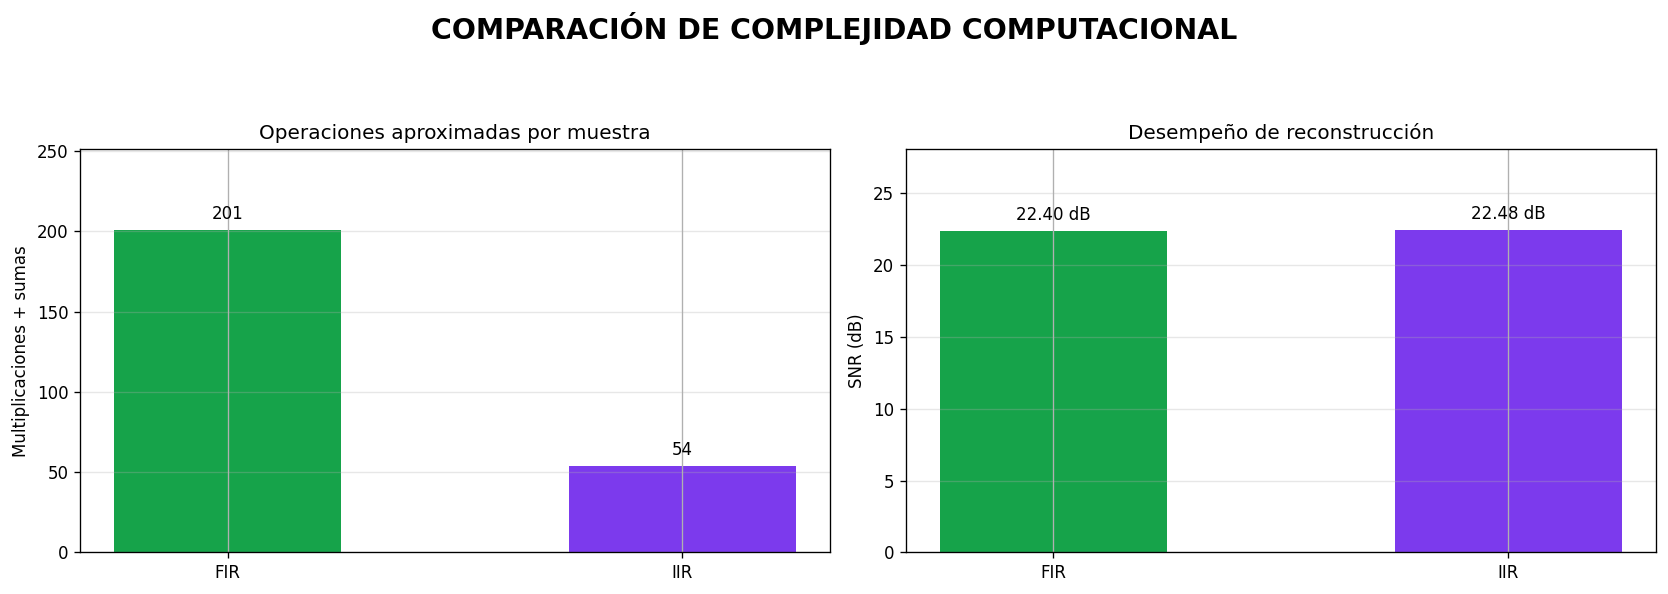

,Parámetro,FIR,IIR
0,Tipo,FIR Hamming,IIR Butterworth
1,Orden,100,6
2,Coeficientes / secciones,101,3
3,Frecuencia de corte (Hz),120,120
4,Multiplicaciones por muestra,101,30
5,Sumas por muestra,100,24
6,Operaciones aproximadas,201,54
7,Método de aplicación,Causal + compensación posterior,Bidireccional (sosfiltfilt)
8,Procesamiento en tiempo real,Posible con retardo,No con este método


COMPARACIÓN COMPUTACIONAL
----------------------------------
FIR: 201 operaciones aproximadas/muestra
IIR: 54 operaciones aproximadas/muestra
Retardo de grupo FIR: 25.0 ms
----------------------------------
Comparación completada correctamente.


In [14]:
# @title

# PASO 12: COMPLEJIDAD COMPUTACIONAL FIR vs IIR
# ACTIVIDAD SUMATIVA N.º 4 - SISTEMAS DE SEÑALES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Parámetros de los filtros
num_coef_fir = len(coef_fir)
num_secciones_iir = len(sos_iir)
num_muestras = len(senal_ruidosa)

# 2. Estimación de operaciones por muestra
# FIR causal: N productos y N-1 sumas
mult_fir = num_coef_fir
sumas_fir = num_coef_fir - 1

# IIR SOS: aproximadamente 5 productos y 4 sumas
# por sección y por pasada, usando forma directa II
# transpuesta. Nuestro IIR usa dos pasadas.
mult_iir = num_secciones_iir * 5 * 2
sumas_iir = num_secciones_iir * 4 * 2

operaciones_fir = mult_fir + sumas_fir
operaciones_iir = mult_iir + sumas_iir

# 3. Tabla técnica
tabla_complejidad = pd.DataFrame({
    "Parámetro": [
        "Tipo",
        "Orden",
        "Coeficientes / secciones",
        "Frecuencia de corte (Hz)",
        "Multiplicaciones por muestra",
        "Sumas por muestra",
        "Operaciones aproximadas",
        "Método de aplicación",
        "Procesamiento en tiempo real"
    ],
    "FIR": [
        "FIR Hamming",
        orden_fir,
        num_coef_fir,
        frecuencia_corte_fir,
        mult_fir,
        sumas_fir,
        operaciones_fir,
        "Causal + compensación posterior",
        "Posible con retardo"
    ],
    "IIR": [
        "IIR Butterworth",
        orden_iir,
        num_secciones_iir,
        frecuencia_corte_iir,
        mult_iir,
        sumas_iir,
        operaciones_iir,
        "Bidireccional (sosfiltfilt)",
        "No con este método"
    ]
})

# 4. Crear presentación gráfica
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fig.suptitle(
    "COMPARACIÓN DE COMPLEJIDAD COMPUTACIONAL",
    fontsize=17,
    fontweight="bold"
)

colores = ["#16A34A", "#7C3AED"]

b1 = axes[0].bar(
    ["FIR", "IIR"],
    [operaciones_fir, operaciones_iir],
    color=colores,
    width=0.5
)

axes[0].set_title("Operaciones aproximadas por muestra")
axes[0].set_ylabel("Multiplicaciones + sumas")
axes[0].bar_label(b1, padding=4)
axes[0].set_ylim(
    0, max(operaciones_fir, operaciones_iir) * 1.25
)
axes[0].grid(axis="y", alpha=0.3)

b2 = axes[1].bar(
    ["FIR", "IIR"],
    [snr_fir, snr_iir],
    color=colores,
    width=0.5
)

axes[1].set_title("Desempeño de reconstrucción")
axes[1].set_ylabel("SNR (dB)")
axes[1].bar_label(b2, fmt="%.2f dB", padding=4)
axes[1].set_ylim(0, max(snr_fir, snr_iir) * 1.25)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.91])

plt.savefig(
    graficas / "figura_11_complejidad_fir_iir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Mostrar y guardar resultados
display(tabla_complejidad)

tabla_complejidad.to_csv(
    resultados / "complejidad_fir_iir.csv",
    index=False
)

print("COMPARACIÓN COMPUTACIONAL")
print("----------------------------------")
print("FIR:", operaciones_fir,
      "operaciones aproximadas/muestra")
print("IIR:", operaciones_iir,
      "operaciones aproximadas/muestra")
print("Retardo de grupo FIR:",
      retardo_fir / fs * 1000, "ms")
print("----------------------------------")
print("Comparación completada correctamente.")


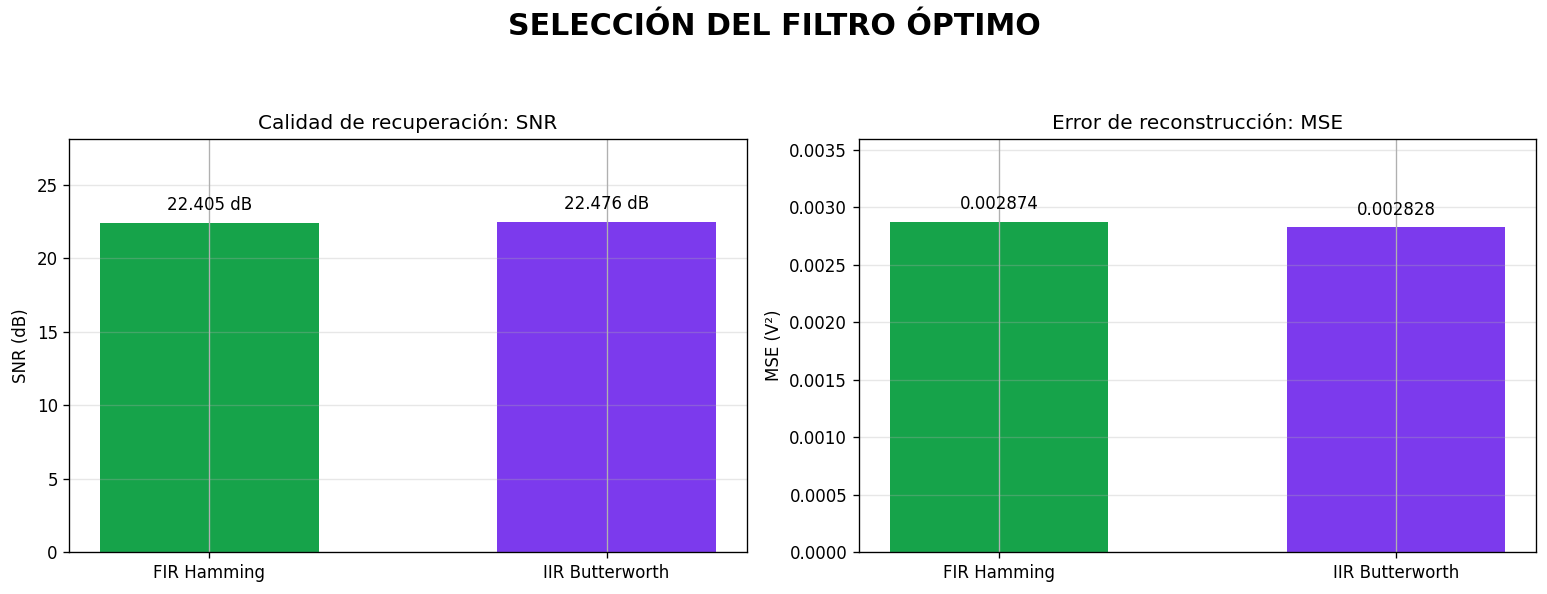

,Indicador,FIR,IIR
0,SNR (dB),22.404919,22.475660
1,MSE (V²),0.002874,0.002828
2,Mejora SNR (dB),15.603717,15.674458
3,Reducción MSE (%),97.248127,97.292589
4,Orden,100.000000,6.000000
5,Operaciones estimadas/muestra,201.000000,54.000000



SELECCIÓN TÉCNICA DEL FILTRO

Filtro seleccionado: IIR Butterworth

FIR:
SNR = 22.4049 dB
MSE = 0.002874 V²

IIR:
SNR = 22.4757 dB
MSE = 0.002828 V²

Diferencia de SNR (IIR - FIR):
0.0707 dB

Diferencia de MSE (FIR - IIR):
0.000046 V²

Los resultados corresponden a una simulación
de medición eléctrica con interferencias.

La selección considera el procesamiento fuera
de línea. El IIR se aplicó bidireccionalmente;
el FIR se aplicó causalmente y se compensó
su retardo de grupo.

Las operaciones computacionales son estimadas.
No se ha demostrado superioridad en tiempo real.



In [19]:
# @title

# PASO 13: SELECCIÓN DEL FILTRO ÓPTIMO
# SISTEMAS DE SEÑALES - ACTIVIDAD SUMATIVA N.º 4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Comparación de resultados calculados
resumen = pd.DataFrame({
    "Indicador": [
        "SNR (dB)",
        "MSE (V²)",
        "Mejora SNR (dB)",
        "Reducción MSE (%)",
        "Orden",
        "Operaciones estimadas/muestra"
    ],
    "FIR": [
        snr_fir, mse_fir, mejora_snr_fir,
        reduccion_mse, orden_fir, operaciones_fir
    ],
    "IIR": [
        snr_iir, mse_iir, mejora_snr_iir,
        reduccion_mse_iir, orden_iir, operaciones_iir
    ]
})

# Selección para procesamiento fuera de línea
if snr_iir > snr_fir and mse_iir < mse_fir:
    filtro_optimo = "IIR Butterworth"
elif snr_fir > snr_iir and mse_fir < mse_iir:
    filtro_optimo = "FIR Hamming"
else:
    filtro_optimo = "Sin ganador único: depende del criterio"

# Gráfica final
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fig.suptitle(
    "SELECCIÓN DEL FILTRO ÓPTIMO",
    fontsize=18, fontweight="bold"
)

nombres = ["FIR Hamming", "IIR Butterworth"]
colores = ["#16A34A", "#7C3AED"]

b1 = axes[0].bar(
    nombres, [snr_fir, snr_iir],
    color=colores, width=0.55
)
axes[0].bar_label(b1, fmt="%.3f dB", padding=5)
axes[0].set_title("Calidad de recuperación: SNR")
axes[0].set_ylabel("SNR (dB)")
axes[0].set_ylim(0, max(snr_fir, snr_iir)*1.25)
axes[0].grid(axis="y", alpha=0.3)

b2 = axes[1].bar(
    nombres, [mse_fir, mse_iir],
    color=colores, width=0.55
)
axes[1].bar_label(b2, fmt="%.6f", padding=5)
axes[1].set_title("Error de reconstrucción: MSE")
axes[1].set_ylabel("MSE (V²)")
axes[1].set_ylim(0, max(mse_fir, mse_iir)*1.25)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.92])

plt.savefig(
    graficas / "figura_12_seleccion_optima.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Guardar resultados
resumen.to_csv(
    resultados / "resumen_final_filtros.csv",
    index=False
)

display(resumen.round(6))

conclusion = f"""
SELECCIÓN TÉCNICA DEL FILTRO

Filtro seleccionado: {filtro_optimo}

FIR:
SNR = {snr_fir:.4f} dB
MSE = {mse_fir:.6f} V²

IIR:
SNR = {snr_iir:.4f} dB
MSE = {mse_iir:.6f} V²

Diferencia de SNR (IIR - FIR):
{snr_iir-snr_fir:.4f} dB

Diferencia de MSE (FIR - IIR):
{mse_fir-mse_iir:.6f} V²

Los resultados corresponden a una simulación
de medición eléctrica con interferencias.

La selección considera el procesamiento fuera
de línea. El IIR se aplicó bidireccionalmente;
el FIR se aplicó causalmente y se compensó
su retardo de grupo.

Las operaciones computacionales son estimadas.
No se ha demostrado superioridad en tiempo real.
"""

print(conclusion)

with open(
    resultados / "conclusion_tecnica.txt",
    "w", encoding="utf-8"
) as archivo:
    archivo.write(conclusion)





In [17]:
# @title

# PASO 14: VERIFICACIÓN DEL PORTAFOLIO DIGITAL
# SISTEMAS DE SEÑALES - SUMATIVA N.º 4

from pathlib import Path
import pandas as pd

# Carpetas del proyecto
carpetas = {
    "Gráficas": graficas,
    "Señales": senales,
    "Resultados": resultados
}

# Revisar archivos generados
registros = []

for categoria, carpeta in carpetas.items():
    for archivo in sorted(carpeta.glob("*")):
        if archivo.is_file():
            registros.append({
                "Categoría": categoria,
                "Archivo": archivo.name,
                "Tamaño (KB)": round(
                    archivo.stat().st_size / 1024, 2
                ),
                "Estado": "Guardado"
            })

tabla_archivos = pd.DataFrame(registros)

print("VERIFICACIÓN DEL PORTAFOLIO DIGITAL")
print("---------------------------------------")

display(tabla_archivos)

print("Total de archivos:", len(tabla_archivos))

# Comprobar archivos esenciales
archivos_necesarios = [
    graficas / "figura_1_senal_original.png",
    graficas / "figura_2_senal_contaminada.png",
    graficas / "figura_3_respuesta_fir.png",
    graficas / "figura_4_filtrado_fir.png",
    graficas / "figura_5_evaluacion_fir.png",
    graficas / "figura_6_analisis_espectral_fir.png",
    graficas / "figura_7_diseno_iir.png",
    graficas / "figura_8_filtrado_iir.png",
    graficas / "figura_9_comparacion_fir_iir.png",
    graficas / "figura_10_comparacion_espectral.png",
    graficas / "figura_11_complejidad_fir_iir.png",
    graficas / "figura_12_seleccion_optima.png"
]

faltantes = [
    archivo.name
    for archivo in archivos_necesarios
    if not archivo.exists()
]

print("---------------------------------------")

if not faltantes:
    print("LAS 12 GRÁFICAS ESTÁN GUARDADAS")
else:
    print("ARCHIVOS PENDIENTES:")
    for nombre in faltantes:
        print("-", nombre)

print("---------------------------------------")
print("Revisión de archivos completada.")


VERIFICACIÓN DEL PORTAFOLIO DIGITAL
---------------------------------------


,Categoría,Archivo,Tamaño (KB),Estado
0,Gráficas,figura_10_comparacion_espectral.png,505.93,Guardado
1,Gráficas,figura_11_complejidad_fir_iir.png,140.92,Guardado
2,Gráficas,figura_12_seleccion_optima.png,153.82,Guardado
3,Gráficas,figura_1_senal_original.png,179.61,Guardado
4,Gráficas,figura_2_senal_contaminada.png,287.70,Guardado
5,Gráficas,figura_3_respuesta_fir.png,283.43,Guardado
6,Gráficas,figura_4_filtrado_fir.png,363.79,Guardado
7,Gráficas,figura_5_evaluacion_fir.png,573.58,Guardado
8,Gráficas,figura_6_analisis_espectral_fir.png,471.12,Guardado
9,Gráficas,figura_7_diseno_iir.png,470.13,Guardado


Total de archivos: 19
---------------------------------------
LAS 12 GRÁFICAS ESTÁN GUARDADAS
---------------------------------------
Revisión de archivos completada.
